# Time Series Practice 1


## Problem Definition — 5W1H

| 5W1H | Nội dung |
|---|---|
| **What** | Phân tích chuỗi thời gian **AirPassengers** để nhận diện **trend, seasonality, autocorrelation, variability** và các vấn đề chất lượng dữ liệu. |
| **Why** | Hiểu cấu trúc của chuỗi và đánh giá dữ liệu có phù hợp để tiếp tục nghiên cứu bài toán **forecasting** hay không. |
| **Who** | Đối tượng phân tích là **số lượng hành khách hàng không quốc tế theo tháng** trong dataset AirPassengers. |
| **When** | Dữ liệu gồm **144 quan sát theo tháng**, từ **01/1949 đến 12/1960**. |
| **Where** | Dataset AirPassengers được lấy từ nguồn CSV công khai của **Rdatasets**: [AirPassengers.csv](https://vincentarelbundock.github.io/Rdatasets/csv/datasets/AirPassengers.csv). Tài liệu tham chiếu: [ETH Zurich R Documentation — AirPassengers](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/AirPassengers.html). |
| **How** | Sử dụng **ACF/PACF, White Noise analysis, STL decomposition, data-quality checks và visualization**; phạm vi chỉ là **exploratory analysis và diagnostics**, chưa huấn luyện mô hình dự báo. |


## Exercise 1 — Phân tích ACF/PACF


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, pacf

from practice_1.analysis import compute_acf_table, compute_pacf_table
from practice_1.data import load_air_passengers
from practice_1.visualization import (
    boolean_cell_color,
    enable_table_theme,
    plot_acf_diagnostic,
    plot_pacf_diagnostic,
    plot_time_series,
    visualise_table,
)


enable_table_theme()




## 1. Nạp dữ liệu AirPassengers


In [2]:
project_root_candidates = (Path.cwd(), Path.cwd().parent)
PROJECT_ROOT = next(
    (
        candidate
        for candidate in project_root_candidates
        if (candidate / "config" / "practice_1.json").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc Practice_1 từ thư mục làm việc hiện tại."
    )

RAW_PATH = PROJECT_ROOT / "datasets" / "raw" / "air_passengers.csv"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"

air_passengers_frame = load_air_passengers(RAW_PATH)
series = air_passengers_frame["passengers_thousands"]

# Cầu nối tương thích cho các Exercise 2–5 hiện có; E1 chỉ dùng dữ liệu canonical ở trên.
df = (
    air_passengers_frame
    .rename(columns={"passengers_thousands": "value"})
    .reset_index()
)

display(visualise_table(
    air_passengers_frame.head().reset_index(),
    "Năm quan sát đầu tiên của AirPassengers",
))


date,passengers_thousands
1949-01-01 00:00:00,112.0000
1949-02-01 00:00:00,118.0000
1949-03-01 00:00:00,132.0000
1949-04-01 00:00:00,129.0000
1949-05-01 00:00:00,121.0000


## 2. Kiểm tra hợp đồng dữ liệu

Các bằng chứng dữ liệu có đúng 144 quan sát theo tháng, từ tháng 01/1949 đến tháng 12/1960, không thiếu giá trị, không trùng timestamp và được sắp xếp theo thời gian.


In [3]:
air_passengers_frame.info()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   passengers_thousands  144 non-null    float64
dtypes: float64(1)
memory usage: 6.3 KB


In [4]:
validation_summary = pd.DataFrame(
    {
        "số_dòng": [len(air_passengers_frame)],
        "số_cột": [air_passengers_frame.shape[1]],
        "cột_phân_tích": [", ".join(air_passengers_frame.columns)],
        "bắt_đầu": [air_passengers_frame.index.min()],
        "kết_thúc": [air_passengers_frame.index.max()],
        "tần_suất": [air_passengers_frame.index.freqstr],
        "giá_trị_thiếu": [int(air_passengers_frame.isna().sum().sum())],
        "timestamp_trùng": [int(air_passengers_frame.index.duplicated().sum())],
        "đúng_thứ_tự_thời_gian": [air_passengers_frame.index.is_monotonic_increasing],
        "đơn_vị": ["nghìn hành khách"],
    }
)
display(
    visualise_table(validation_summary, "Hợp đồng và chất lượng dữ liệu đầu vào")
    .map(boolean_cell_color, subset=["đúng_thứ_tự_thời_gian"])
)


số_dòng,số_cột,cột_phân_tích,bắt_đầu,kết_thúc,tần_suất,giá_trị_thiếu,timestamp_trùng,đúng_thứ_tự_thời_gian,đơn_vị
144,1,passengers_thousands,1949-01-01 00:00:00,1960-12-01 00:00:00,MS,0,0,True,nghìn hành khách


In [5]:
descriptive_summary = (
    air_passengers_frame.describe()
    .T
    .reset_index(names="biến")
)
display(visualise_table(
    descriptive_summary,
    "Thống kê mô tả AirPassengers",
    gradient_columns=["mean", "std", "min", "max"],
))


biến,count,mean,std,min,25%,50%,75%,max
passengers_thousands,144.0000,280.2986,119.9663,104.0000,180.0000,265.5000,360.5000,622.0000


## 3. Quan sát chuỗi thời gian gốc


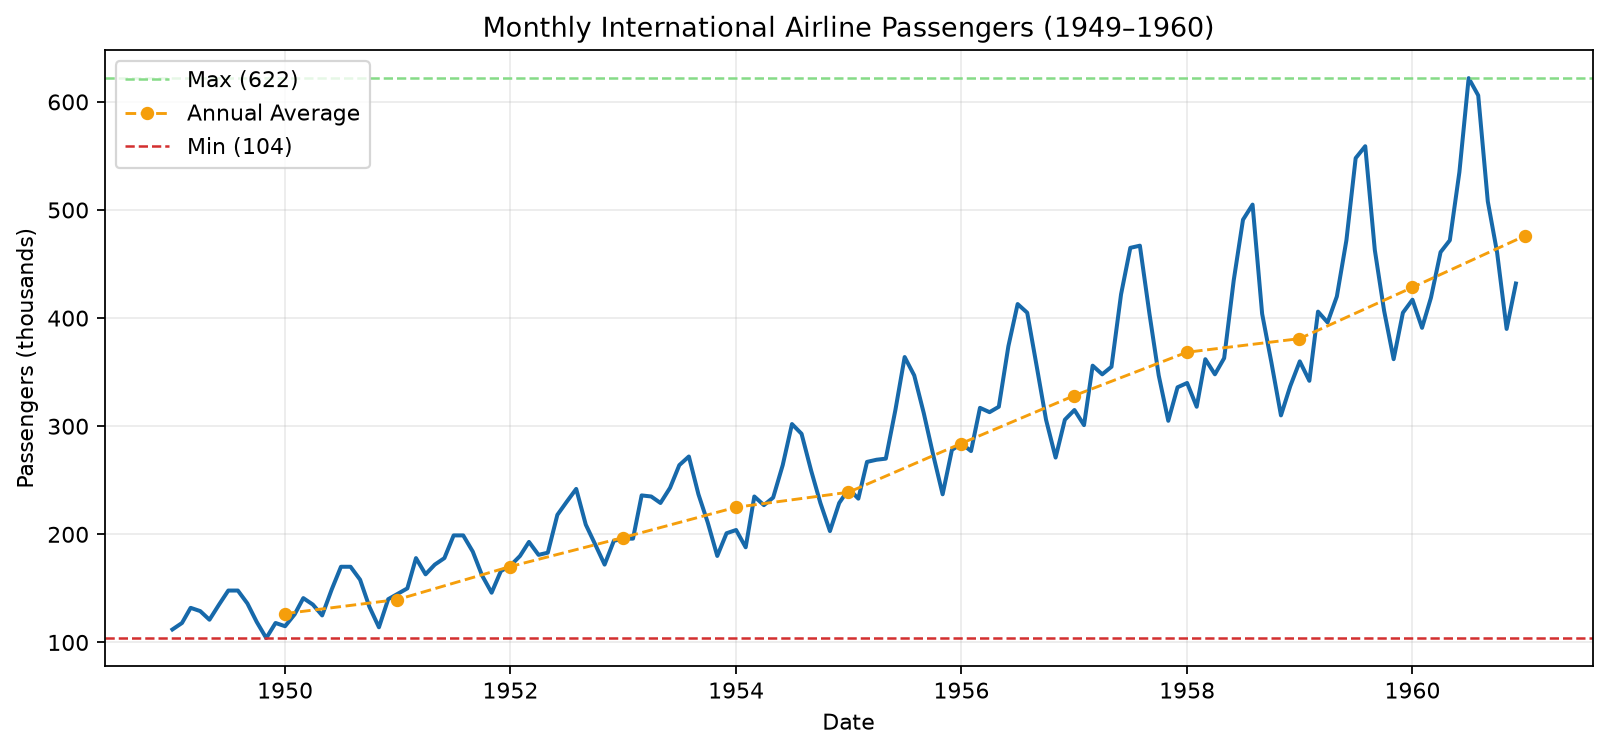

In [6]:
time_series_figure = FIGURES_DIR / "01_time_series_overview.png"
plot_time_series(air_passengers_frame, time_series_figure)
display(Image(filename=str(time_series_figure)))


Chuỗi gồm số hành khách quốc tế theo tháng, đơn vị **nghìn hành khách**, từ tháng 01/1949 đến tháng 12/1960. Biểu đồ cho thấy:

- xu hướng tăng rõ rệt;
- mẫu mùa vụ lặp lại theo năm;
- biên độ dao động mùa vụ tăng cùng mức của chuỗi.

Các đặc điểm này cho thấy chuỗi gốc chưa dừng và có cấu trúc mùa vụ. Nhận xét này chỉ mô tả dữ liệu, chưa phải bước lựa chọn mô hình.


## 4. Phương pháp ACF và PACF

ACF tại độ trễ k đo tương quan giữa giá trị hiện tại X(t) và giá trị quá khứ X(t-k). Dạng tổng quát:

`r(k) = tổng[(X(t) - trung bình) × (X(t-k) - trung bình)] / tổng[(X(t) - trung bình)²]`

PACF đo tương quan trực tiếp giữa X(t) và X(t-k) sau khi kiểm soát ảnh hưởng tuyến tính của các độ trễ trung gian.

E1 sử dụng tối đa 40 độ trễ, mức tin cậy 95% (`alpha=0.05`) và phương pháp PACF `ywm`. ACF/PACF trên chuỗi gốc được dùng để khám phá cấu trúc phụ thuộc, không dùng để tự động chọn bậc ARIMA/SARIMA.


In [7]:
MAX_LAG = 40
ALPHA = 0.05
PACF_METHOD = "ywm"

acf_table = compute_acf_table(series, max_lag=MAX_LAG, alpha=ALPHA)
pacf_table = compute_pacf_table(
    series,
    max_lag=MAX_LAG,
    alpha=ALPHA,
    method=PACF_METHOD,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
acf_table.to_csv(RESULTS_DIR / "acf_values.csv", index=False)
pacf_table.to_csv(RESULTS_DIR / "pacf_values.csv", index=False)

# Các tên này được giữ để không làm thay đổi logic của Exercise 2–5.
lags = acf_table["lag"].to_numpy()
acf_values = acf_table["acf"].to_numpy()
pacf_values = pacf_table["pacf"].to_numpy()

display(visualise_table(
    acf_table.head(),
    "Năm giá trị ACF đầu tiên",
    gradient_columns=["acf"],
))


lag,acf,lower_ci,upper_ci
0,1.0000,1.0000,1.0000
1,0.9480,0.7847,1.1114
2,0.8756,0.6024,1.1488
3,0.8067,0.4668,1.1466
4,0.7526,0.3650,1.1402


In [8]:
selected_acf = (
    acf_table.set_index("lag")
    .loc[[1, 12, 24, 36], ["acf", "lower_ci", "upper_ci"]]
    .reset_index()
)
selected_acf["khoảng_tin_cậy_95%_không_chứa_0"] = (
    (selected_acf["lower_ci"] > 0) | (selected_acf["upper_ci"] < 0)
)
display(
    visualise_table(
        selected_acf,
        "ACF tại các độ trễ quan trọng",
        gradient_columns=["acf"],
    ).map(
        boolean_cell_color,
        subset=["khoảng_tin_cậy_95%_không_chứa_0"],
    )
)


lag,acf,lower_ci,upper_ci,khoảng_tin_cậy_95%_không_chứa_0
1,0.9480,0.7847,1.1114,True
12,0.7604,0.1615,1.3593,True
24,0.5322,-0.2140,1.2783,False
36,0.3370,-0.4639,1.1379,False


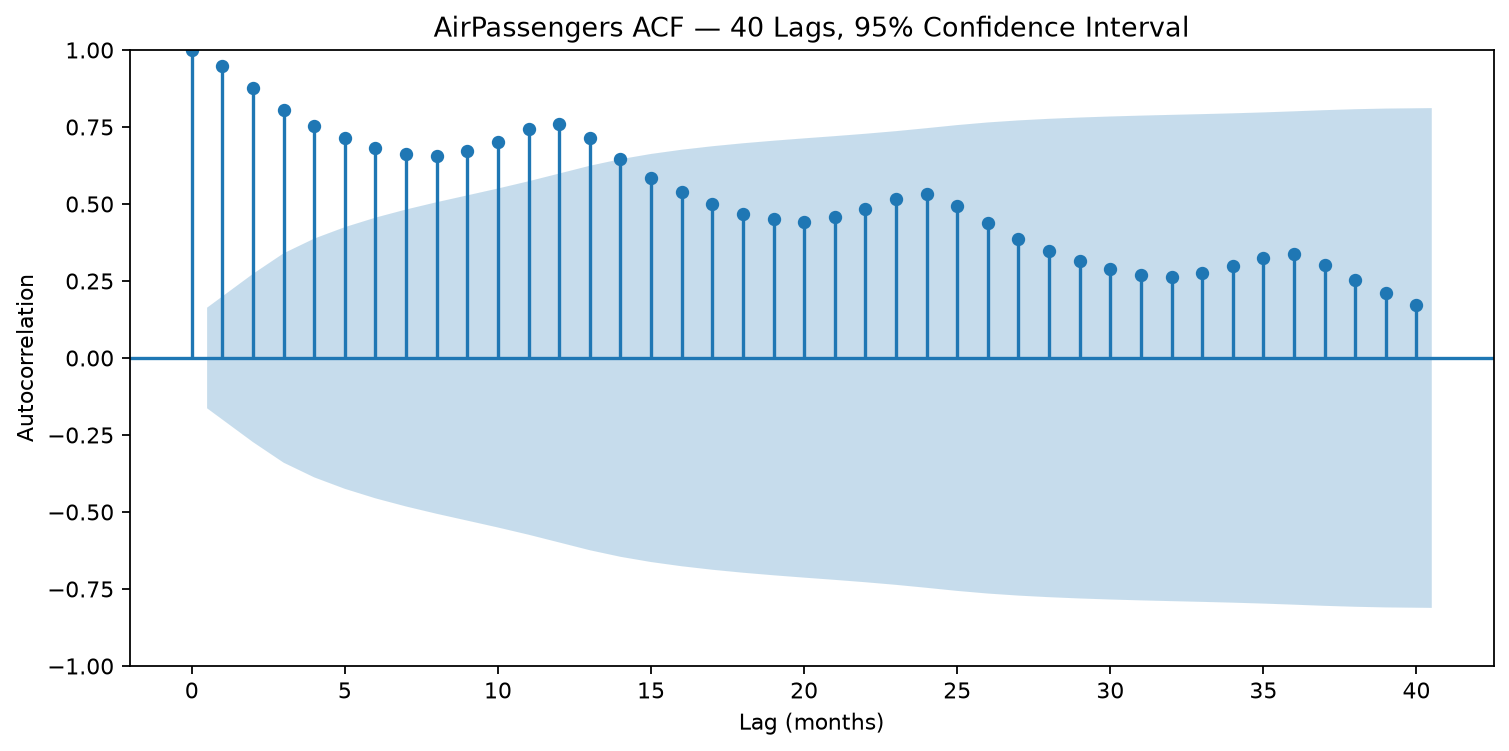

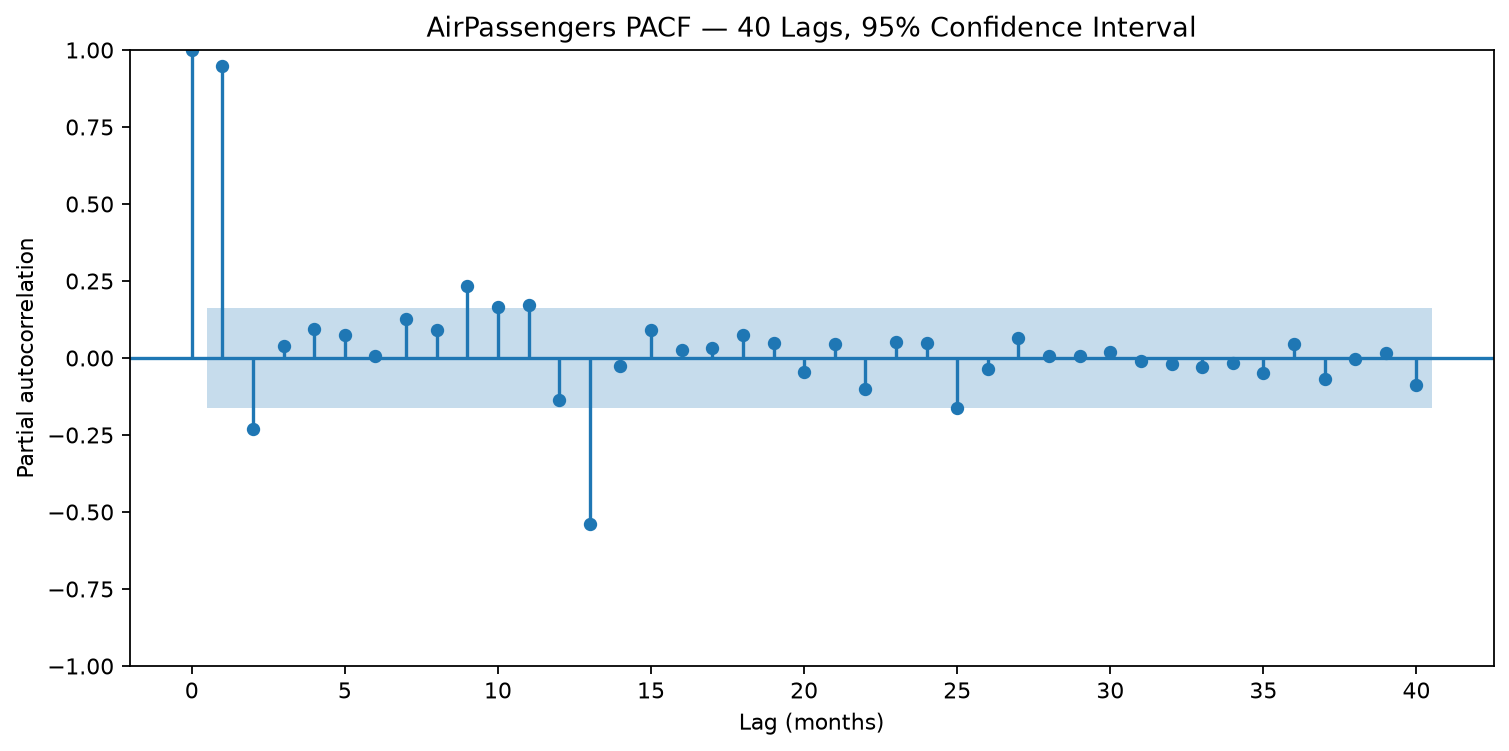

In [9]:
acf_figure = FIGURES_DIR / "02_acf_40_lags.png"
pacf_figure = FIGURES_DIR / "03_pacf_40_lags.png"

plot_acf_diagnostic(series, acf_figure, max_lag=MAX_LAG, alpha=ALPHA)
plot_pacf_diagnostic(
    series,
    pacf_figure,
    max_lag=MAX_LAG,
    alpha=ALPHA,
    method=PACF_METHOD,
)

display(Image(filename=str(acf_figure)))
display(Image(filename=str(pacf_figure)))


## 5. Bằng chứng định lượng


In [10]:
acf_significant_lags = (
    acf_table.loc[
        acf_table["lag"].ne(0)
        & ((acf_table["lower_ci"] > 0) | (acf_table["upper_ci"] < 0)),
        "lag",
    ]
    .astype(int)
    .tolist()
)
pacf_significant_lags = (
    pacf_table.loc[
        pacf_table["lag"].ne(0)
        & ((pacf_table["lower_ci"] > 0) | (pacf_table["upper_ci"] < 0)),
        "lag",
    ]
    .astype(int)
    .tolist()
)
top_absolute_pacf_lags = (
    pacf_table.loc[pacf_table["lag"].ne(0)]
    .assign(abs_pacf=lambda table: table["pacf"].abs())
    .nlargest(10, "abs_pacf")["lag"]
    .astype(int)
    .tolist()
)

findings = {
    "acf_lag_1": float(acf_table.loc[acf_table["lag"].eq(1), "acf"].iloc[0]),
    "acf_significant_lags": acf_significant_lags,
    "pacf_significant_lags": pacf_significant_lags,
    "seasonal_acf": {
        str(lag): float(acf_table.loc[acf_table["lag"].eq(lag), "acf"].iloc[0])
        for lag in (12, 24, 36)
    },
    "top_absolute_pacf_lags": top_absolute_pacf_lags,
}
(RESULTS_DIR / "exercise_01_findings.json").write_text(
    json.dumps(findings, indent=2) + chr(10),
    encoding="utf-8",
)
findings


{'acf_lag_1': 0.9480473407524913,
 'acf_significant_lags': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 'pacf_significant_lags': [1, 2, 9, 10, 11, 13],
 'seasonal_acf': {'12': 0.7603950422625558,
  '24': 0.5321898304658021,
  '36': 0.33702359902053575},
 'top_absolute_pacf_lags': [1, 13, 9, 2, 11, 10, 25, 12, 7, 22]}

In [11]:
selected_pacf = (
    pacf_table.set_index("lag")
    .loc[[1, 13], ["pacf", "lower_ci", "upper_ci"]]
    .reset_index()
)
selected_pacf["khoảng_tin_cậy_95%_không_chứa_0"] = (
    (selected_pacf["lower_ci"] > 0) | (selected_pacf["upper_ci"] < 0)
)
display(
    visualise_table(
        selected_pacf,
        "PACF tại các độ trễ nổi bật",
        gradient_columns=["pacf"],
        gradient_cmap="coolwarm",
    ).map(
        boolean_cell_color,
        subset=["khoảng_tin_cậy_95%_không_chứa_0"],
    )
)


lag,pacf,lower_ci,upper_ci,khoảng_tin_cậy_95%_không_chứa_0
1,0.9480,0.7847,1.1114,True
13,-0.5397,-0.7030,-0.3764,True


## 6. Trả lời câu hỏi Exercise 1

### 6.1. Chuỗi có tự tương quan mạnh không?

Có. ACF tại độ trễ 1 bằng khoảng **0.9480**, cho thấy giá trị của hai tháng liền kề phụ thuộc tuyến tính rất mạnh. Chuỗi gốc không có đặc điểm của white noise.

### 6.2. ACF giảm nhanh hay giảm chậm?

ACF giảm chậm và còn dương qua nhiều độ trễ. Đây là bằng chứng mô tả phù hợp với xu hướng tăng và trạng thái chưa dừng quan sát được trên biểu đồ chuỗi.

### 6.3. Có mẫu lặp lại theo chu kỳ không?

Có dấu hiệu lặp theo chu kỳ 12 tháng. ACF tăng trở lại quanh các độ trễ mùa vụ và có các giá trị:

| Độ trễ | ACF |
|---:|---:|
| 12 | 0.7604 |
| 24 | 0.5322 |
| 36 | 0.3370 |

Mức tương quan giảm dần khi khoảng cách thời gian tăng nhưng vẫn tạo thành mẫu dương tại các bội số của 12.

### 6.4. Bằng chứng ở độ trễ 12, 24 và 36 là gì?

Độ trễ 12 có khoảng tin cậy 95% không chứa 0 nên là bằng chứng thống kê rõ nhất trong ba độ trễ mùa vụ. ACF tại 24 và 36 vẫn dương nhưng khoảng tin cậy 95% chứa 0; vì vậy chúng hỗ trợ nhận diện mẫu lặp, nhưng không nên được mô tả riêng lẻ là có ý nghĩa thống kê ở mức 5%.

PACF nổi bật nhất tại độ trễ 1. Độ trễ 13 có PACF khoảng **-0.5397** và khoảng tin cậy không chứa 0, nhưng không được diễn giải thành bậc AR khi chuỗi gốc còn chưa dừng.

### 6.5. Lag nào quan trọng nhất?

**Lag 1** là độ trễ quan trọng nhất đối với phụ thuộc ngắn hạn vì có ACF khoảng **0.9480** và PACF nổi bật nhất. **Lag 12** là độ trễ mùa vụ quan trọng nhất vì đại diện cho chu kỳ lặp hằng năm và có ACF khoảng **0.7604**.


# Exercise 2 — White Noise

Mục tiêu của E2 là sinh chuỗi white noise có thể tái tạo, kiểm tra thống kê mô tả và ACF đến 40 độ trễ, sau đó so sánh với ACF AirPassengers đã được E1 kiểm chứng.

Tham số cố định: 1.000 quan sát, `numpy.random.default_rng(42)`, phân phối Normal(0, 1) và khoảng tin cậy 95%.


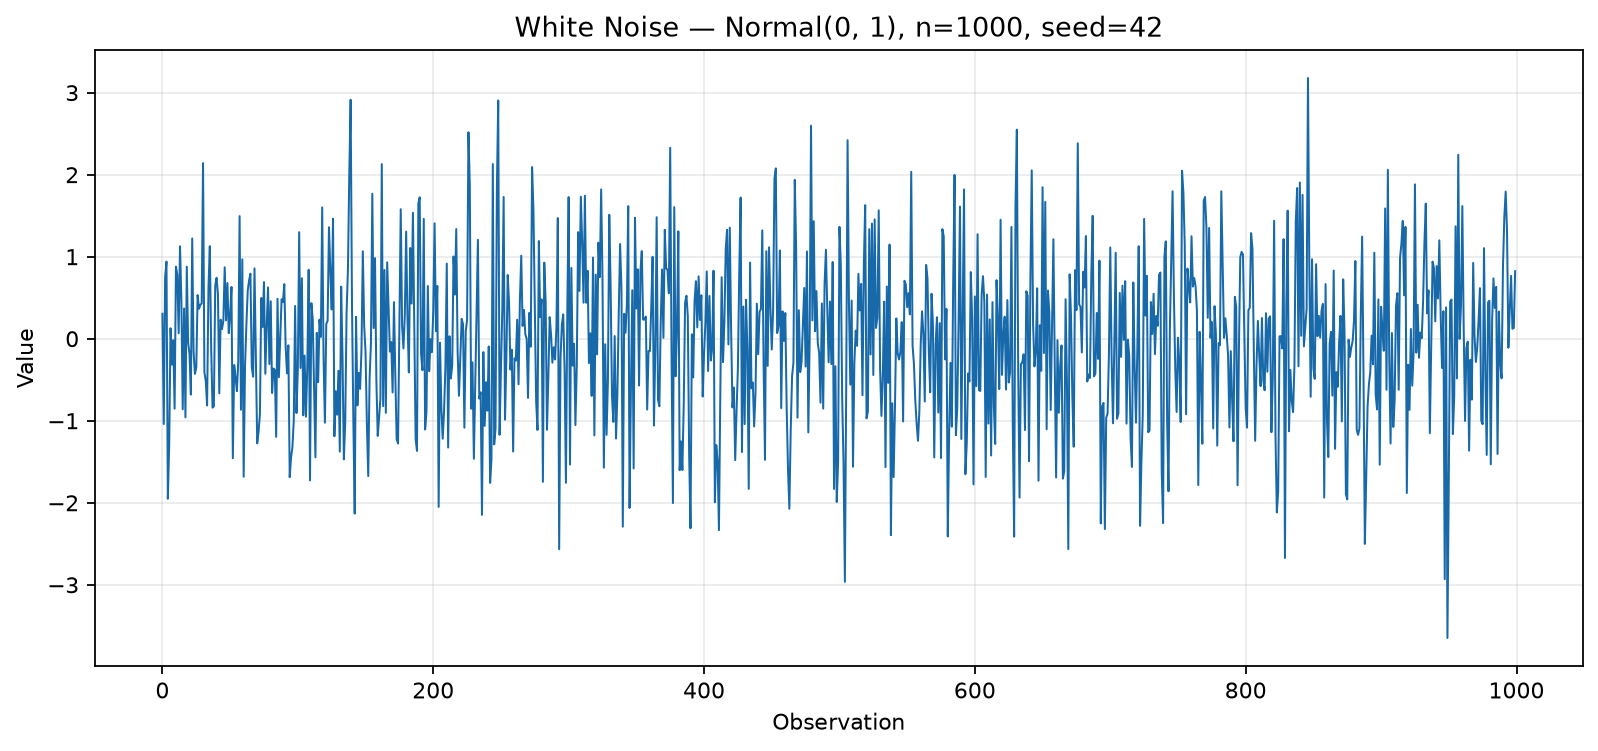

số_quan_sát,trung_bình_mẫu,độ_lệch_chuẩn_mẫu,seed,phân_phối
"1,000",-0.0289,0.9892,42,"Normal(0, 1)"


In [12]:
from IPython.display import Markdown
from practice_1.analysis import generate_white_noise
from practice_1.visualization import (
    plot_acf_comparison,
    plot_acf_table,
    plot_white_noise_series,
)

WHITE_NOISE_SIZE = 1000
WHITE_NOISE_SEED = 42
WHITE_NOISE_MEAN = 0.0
WHITE_NOISE_STANDARD_DEVIATION = 1.0

white_noise = generate_white_noise(
    size=WHITE_NOISE_SIZE,
    seed=WHITE_NOISE_SEED,
    mean=WHITE_NOISE_MEAN,
    standard_deviation=WHITE_NOISE_STANDARD_DEVIATION,
)

white_noise_summary = pd.DataFrame(
    {
        "số_quan_sát": [len(white_noise)],
        "trung_bình_mẫu": [white_noise.mean()],
        "độ_lệch_chuẩn_mẫu": [white_noise.std(ddof=1)],
        "seed": [WHITE_NOISE_SEED],
        "phân_phối": ["Normal(0, 1)"],
    }
)

white_noise_figure = FIGURES_DIR / "04_white_noise_series.png"
plot_white_noise_series(white_noise, white_noise_figure)
display(Image(filename=str(white_noise_figure)))
display(visualise_table(
    white_noise_summary,
    "Thông tin chuỗi white noise mô phỏng",
))


### Công thức tính ngưỡng tin cậy 95% của ACF

Đối với chuỗi White Noise có \(n\) quan sát, ngưỡng tin cậy 95% xấp xỉ được tính bằng:

$$
CI_{95\%} = \pm \frac{1.96}{\sqrt{n}}
$$

Trong đó:

- \(CI_{95\%}\): ngưỡng tin cậy 95%.
- \(1.96\): giá trị tới hạn của phân phối chuẩn ở mức tin cậy 95% hai phía.
- \(n\): số lượng quan sát trong chuỗi thời gian.

**Ví dụ:** Với \(n = 1000\) quan sát:

$$
CI_{95\%} = \pm \frac{1.96}{\sqrt{1000}}
\approx \pm 0.062
$$

**Cách diễn giải:**

- Nếu hệ số ACF nằm trong khoảng \([-0.062, 0.062]\), chưa có đủ bằng chứng để kết luận hệ số tự tương quan tại lag đó khác 0 ở mức ý nghĩa 5%.
- Nếu hệ số ACF nằm ngoài khoảng này, hệ số tự tương quan tại lag đó có thể có ý nghĩa thống kê ở mức 5%.

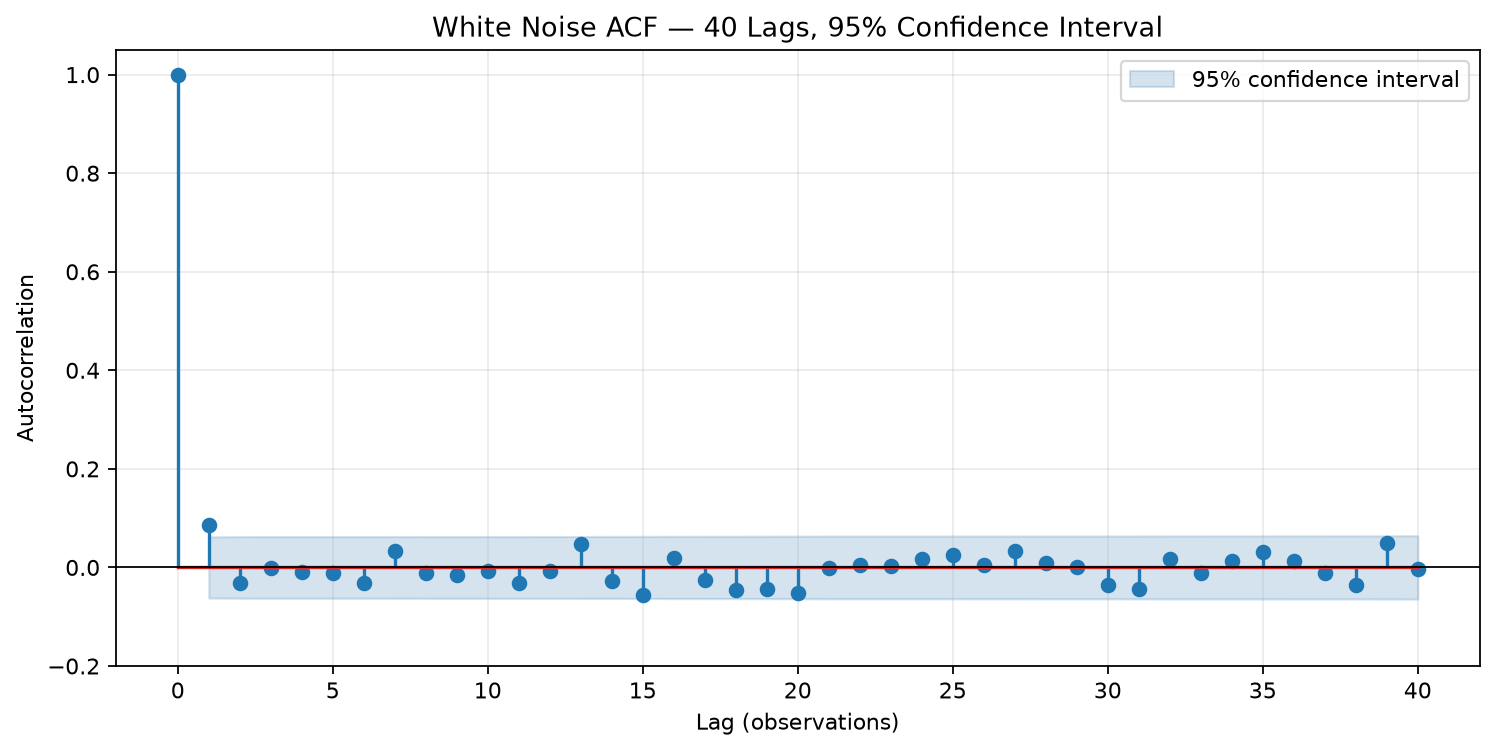

ngưỡng_xấp_xỉ_95%,số_lag_1_đến_40_vượt_CI,các_lag_vượt_CI
0.0620,1,[1]


In [13]:
white_noise_acf_table = compute_acf_table(
    white_noise,
    max_lag=MAX_LAG,
    alpha=ALPHA,
)
white_noise_acf_table.to_csv(
    RESULTS_DIR / "white_noise_acf_values.csv",
    index=False,
)

white_noise_significant_lags = (
    white_noise_acf_table.loc[
        white_noise_acf_table["lag"].ne(0)
        & (
            (white_noise_acf_table["lower_ci"] > 0)
            | (white_noise_acf_table["upper_ci"] < 0)
        ),
        "lag",
    ]
    .astype(int)
    .tolist()
)
approximate_confidence_bound = 1.96 / np.sqrt(len(white_noise))

white_noise_acf_figure = FIGURES_DIR / "05_white_noise_acf.png"
plot_acf_table(
    white_noise_acf_table,
    white_noise_acf_figure,
    title="White Noise ACF — 40 Lags, 95% Confidence Interval",
)
display(Image(filename=str(white_noise_acf_figure)))

white_noise_acf_summary = pd.DataFrame(
    {
        "ngưỡng_xấp_xỉ_95%": [approximate_confidence_bound],
        "số_lag_1_đến_40_vượt_CI": [len(white_noise_significant_lags)],
        "các_lag_vượt_CI": [white_noise_significant_lags],
    }
)
display(visualise_table(
    white_noise_acf_summary,
    "Tóm tắt ACF của white noise",
))


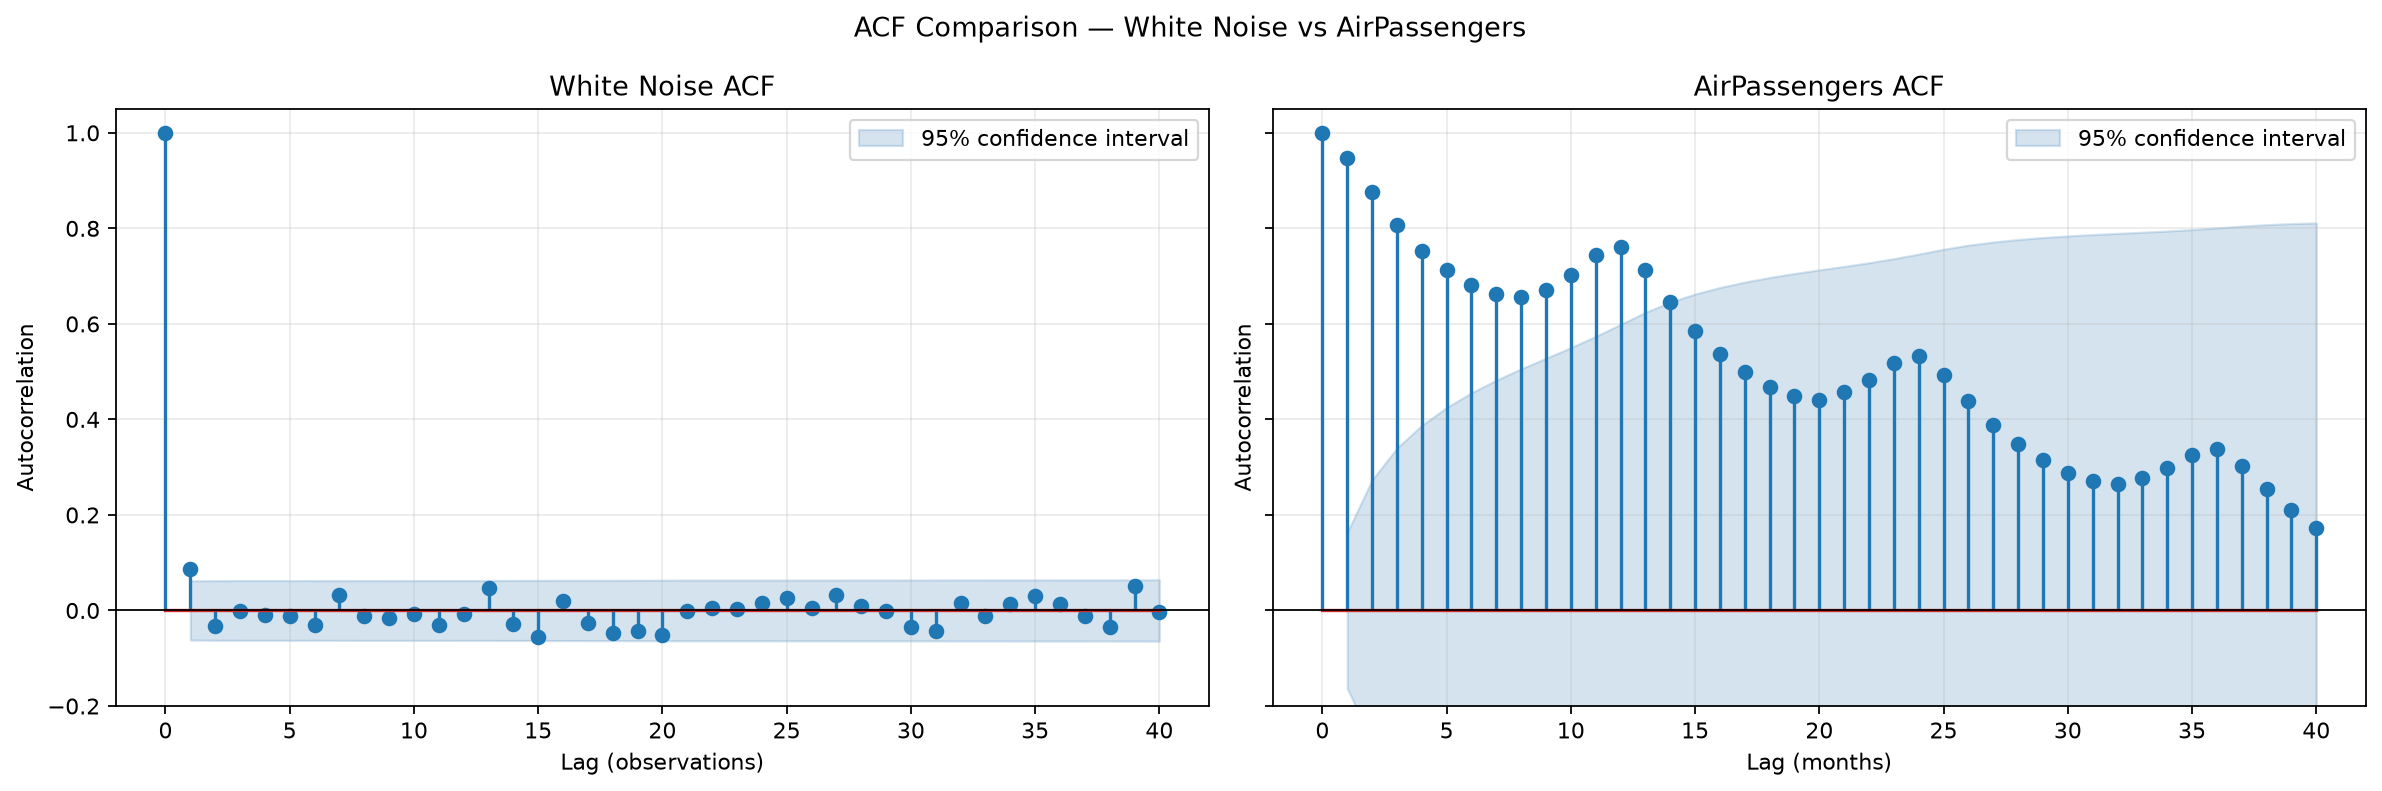

chuỗi,ACF_lag_1,số_lag_1_đến_40_vượt_CI
White Noise,0.0871,1
AirPassengers,0.9480,14


In [14]:
air_acf_reference = pd.read_csv(RESULTS_DIR / "acf_values.csv")
expected_acf_columns = ["lag", "acf", "lower_ci", "upper_ci"]

if air_acf_reference.columns.tolist() != expected_acf_columns:
    raise ValueError("Validated AirPassengers ACF has an unexpected schema")
if air_acf_reference["lag"].tolist() != list(range(MAX_LAG + 1)):
    raise ValueError("Validated AirPassengers ACF does not cover lags 0–40")
if not np.allclose(
    air_acf_reference["acf"].to_numpy(),
    acf_table["acf"].to_numpy(),
):
    raise ValueError("Validated AirPassengers ACF does not match the E1 result")

comparison_figure = FIGURES_DIR / "06_white_noise_vs_airpassengers_acf.png"
plot_acf_comparison(
    white_noise_acf_table,
    air_acf_reference,
    comparison_figure,
)
display(Image(filename=str(comparison_figure)))

air_significant_lags = (
    air_acf_reference.loc[
        air_acf_reference["lag"].ne(0)
        & (
            (air_acf_reference["lower_ci"] > 0)
            | (air_acf_reference["upper_ci"] < 0)
        ),
        "lag",
    ]
    .astype(int)
    .tolist()
)

acf_comparison_summary = pd.DataFrame(
    {
        "chuỗi": ["White Noise", "AirPassengers"],
        "ACF_lag_1": [
            white_noise_acf_table.loc[1, "acf"],
            air_acf_reference.loc[1, "acf"],
        ],
        "số_lag_1_đến_40_vượt_CI": [
            len(white_noise_significant_lags),
            len(air_significant_lags),
        ],
    }
)
display(visualise_table(
    acf_comparison_summary,
    "So sánh ACF: White Noise và AirPassengers",
    gradient_columns=["ACF_lag_1", "số_lag_1_đến_40_vượt_CI"],
))


In [15]:
white_mean = float(white_noise.mean())
white_sample_std = float(white_noise.std(ddof=1))
white_lag_1 = float(white_noise_acf_table.loc[1, "acf"])
air_lag_1 = float(air_acf_reference.loc[1, "acf"])
air_lag_12 = float(air_acf_reference.loc[12, "acf"])
air_lag_24 = float(air_acf_reference.loc[24, "acf"])
air_lag_36 = float(air_acf_reference.loc[36, "acf"])
outside_lags = ", ".join(map(str, white_noise_significant_lags))

comparison_markdown = chr(10).join(
    [
        "## Phân tích kết quả Exercise 2",
        "",
        f"1. White noise dao động ngẫu nhiên quanh 0, không có xu hướng hay chu kỳ ổn định; trung bình mẫu là **{white_mean:.4f}** và độ lệch chuẩn mẫu là **{white_sample_std:.4f}**, gần các tham số lý thuyết 0 và 1.",
        "",
        f"2. Trong 40 độ trễ khác 0 của white noise, chỉ có **{len(white_noise_significant_lags)}** lag vượt khoảng tin cậy 95% (lag **{outside_lags}**, ACF khoảng **{white_lag_1:.4f}**); một spike riêng lẻ có thể xuất hiện ngẫu nhiên và không phủ nhận hành vi white noise.",
        "",
        f"3. AirPassengers có phụ thuộc thời gian mạnh hơn rõ rệt: ACF tại lag 1 khoảng **{air_lag_1:.4f}**, lớn hơn nhiều white noise, và có nhiều lag đầu vượt khoảng tin cậy.",
        "",
        f"4. ACF của AirPassengers giảm chậm và lặp theo chu kỳ 12 tháng, với ACF tại lag 12, 24 và 36 lần lượt khoảng **{air_lag_12:.4f}**, **{air_lag_24:.4f}** và **{air_lag_36:.4f}**.",
        "",
        "5. Vì vậy, white noise là mốc của chuỗi gần như không có cấu trúc phụ thuộc tuyến tính, còn AirPassengers thể hiện xu hướng, tự tương quan mạnh và mùa vụ rõ ràng.",
    ]
)

display(Markdown(comparison_markdown))


## Phân tích kết quả Exercise 2

1. White noise dao động ngẫu nhiên quanh 0, không có xu hướng hay chu kỳ ổn định; trung bình mẫu là **-0.0289** và độ lệch chuẩn mẫu là **0.9892**, gần các tham số lý thuyết 0 và 1.

2. Trong 40 độ trễ khác 0 của white noise, chỉ có **1** lag vượt khoảng tin cậy 95% (lag **1**, ACF khoảng **0.0871**); một spike riêng lẻ có thể xuất hiện ngẫu nhiên và không phủ nhận hành vi white noise.

3. AirPassengers có phụ thuộc thời gian mạnh hơn rõ rệt: ACF tại lag 1 khoảng **0.9480**, lớn hơn nhiều white noise, và có nhiều lag đầu vượt khoảng tin cậy.

4. ACF của AirPassengers giảm chậm và lặp theo chu kỳ 12 tháng, với ACF tại lag 12, 24 và 36 lần lượt khoảng **0.7604**, **0.5322** và **0.3370**.

5. Vì vậy, white noise là mốc của chuỗi gần như không có cấu trúc phụ thuộc tuyến tính, còn AirPassengers thể hiện xu hướng, tự tương quan mạnh và mùa vụ rõ ràng.

## Exercise 3 — Phân rã chuỗi thời gian    
AirPassengers được biến đổi bằng log tự nhiên trước khi phân rã STL với chu kỳ 12 tháng và `robust=True`.

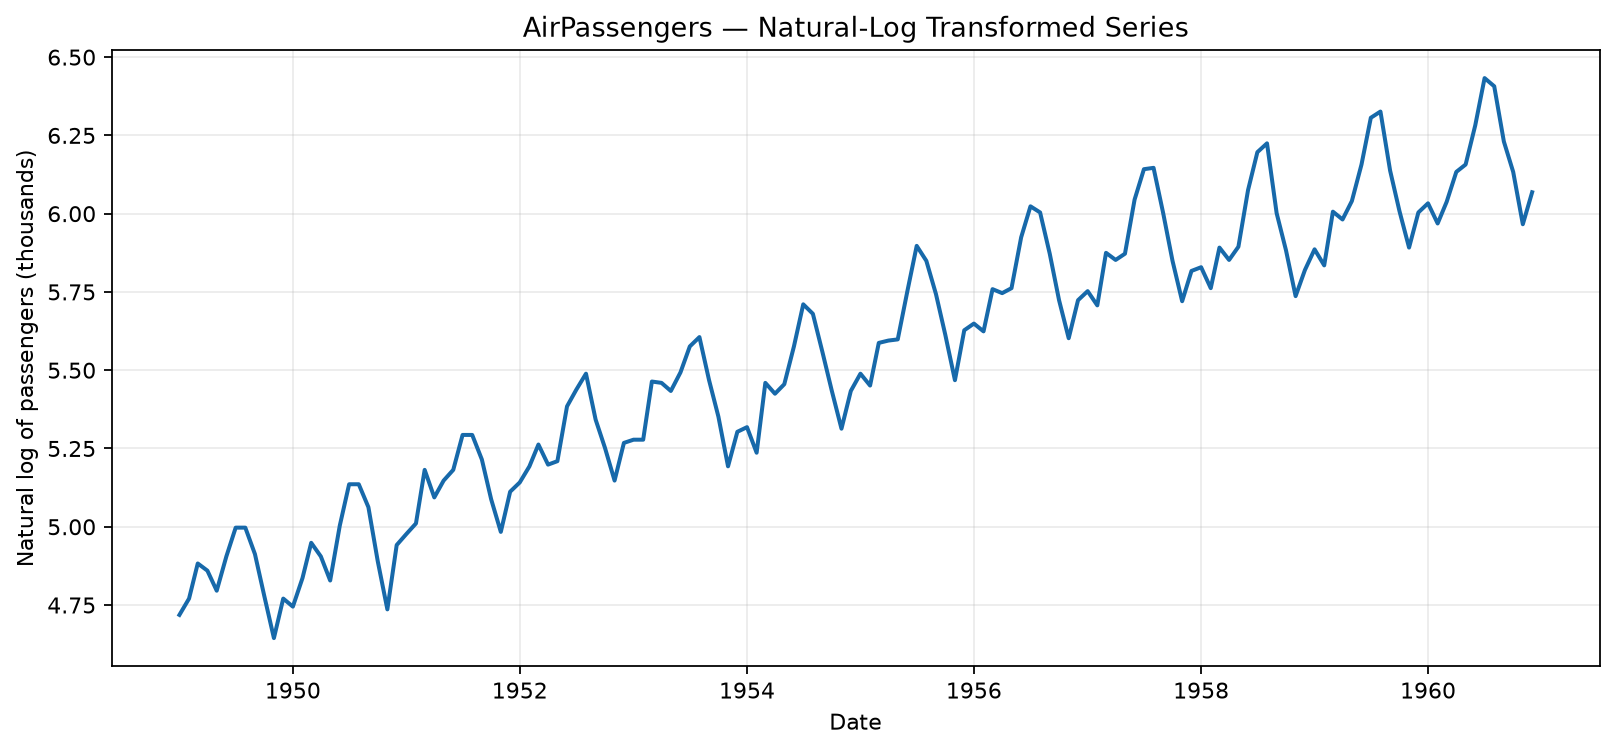

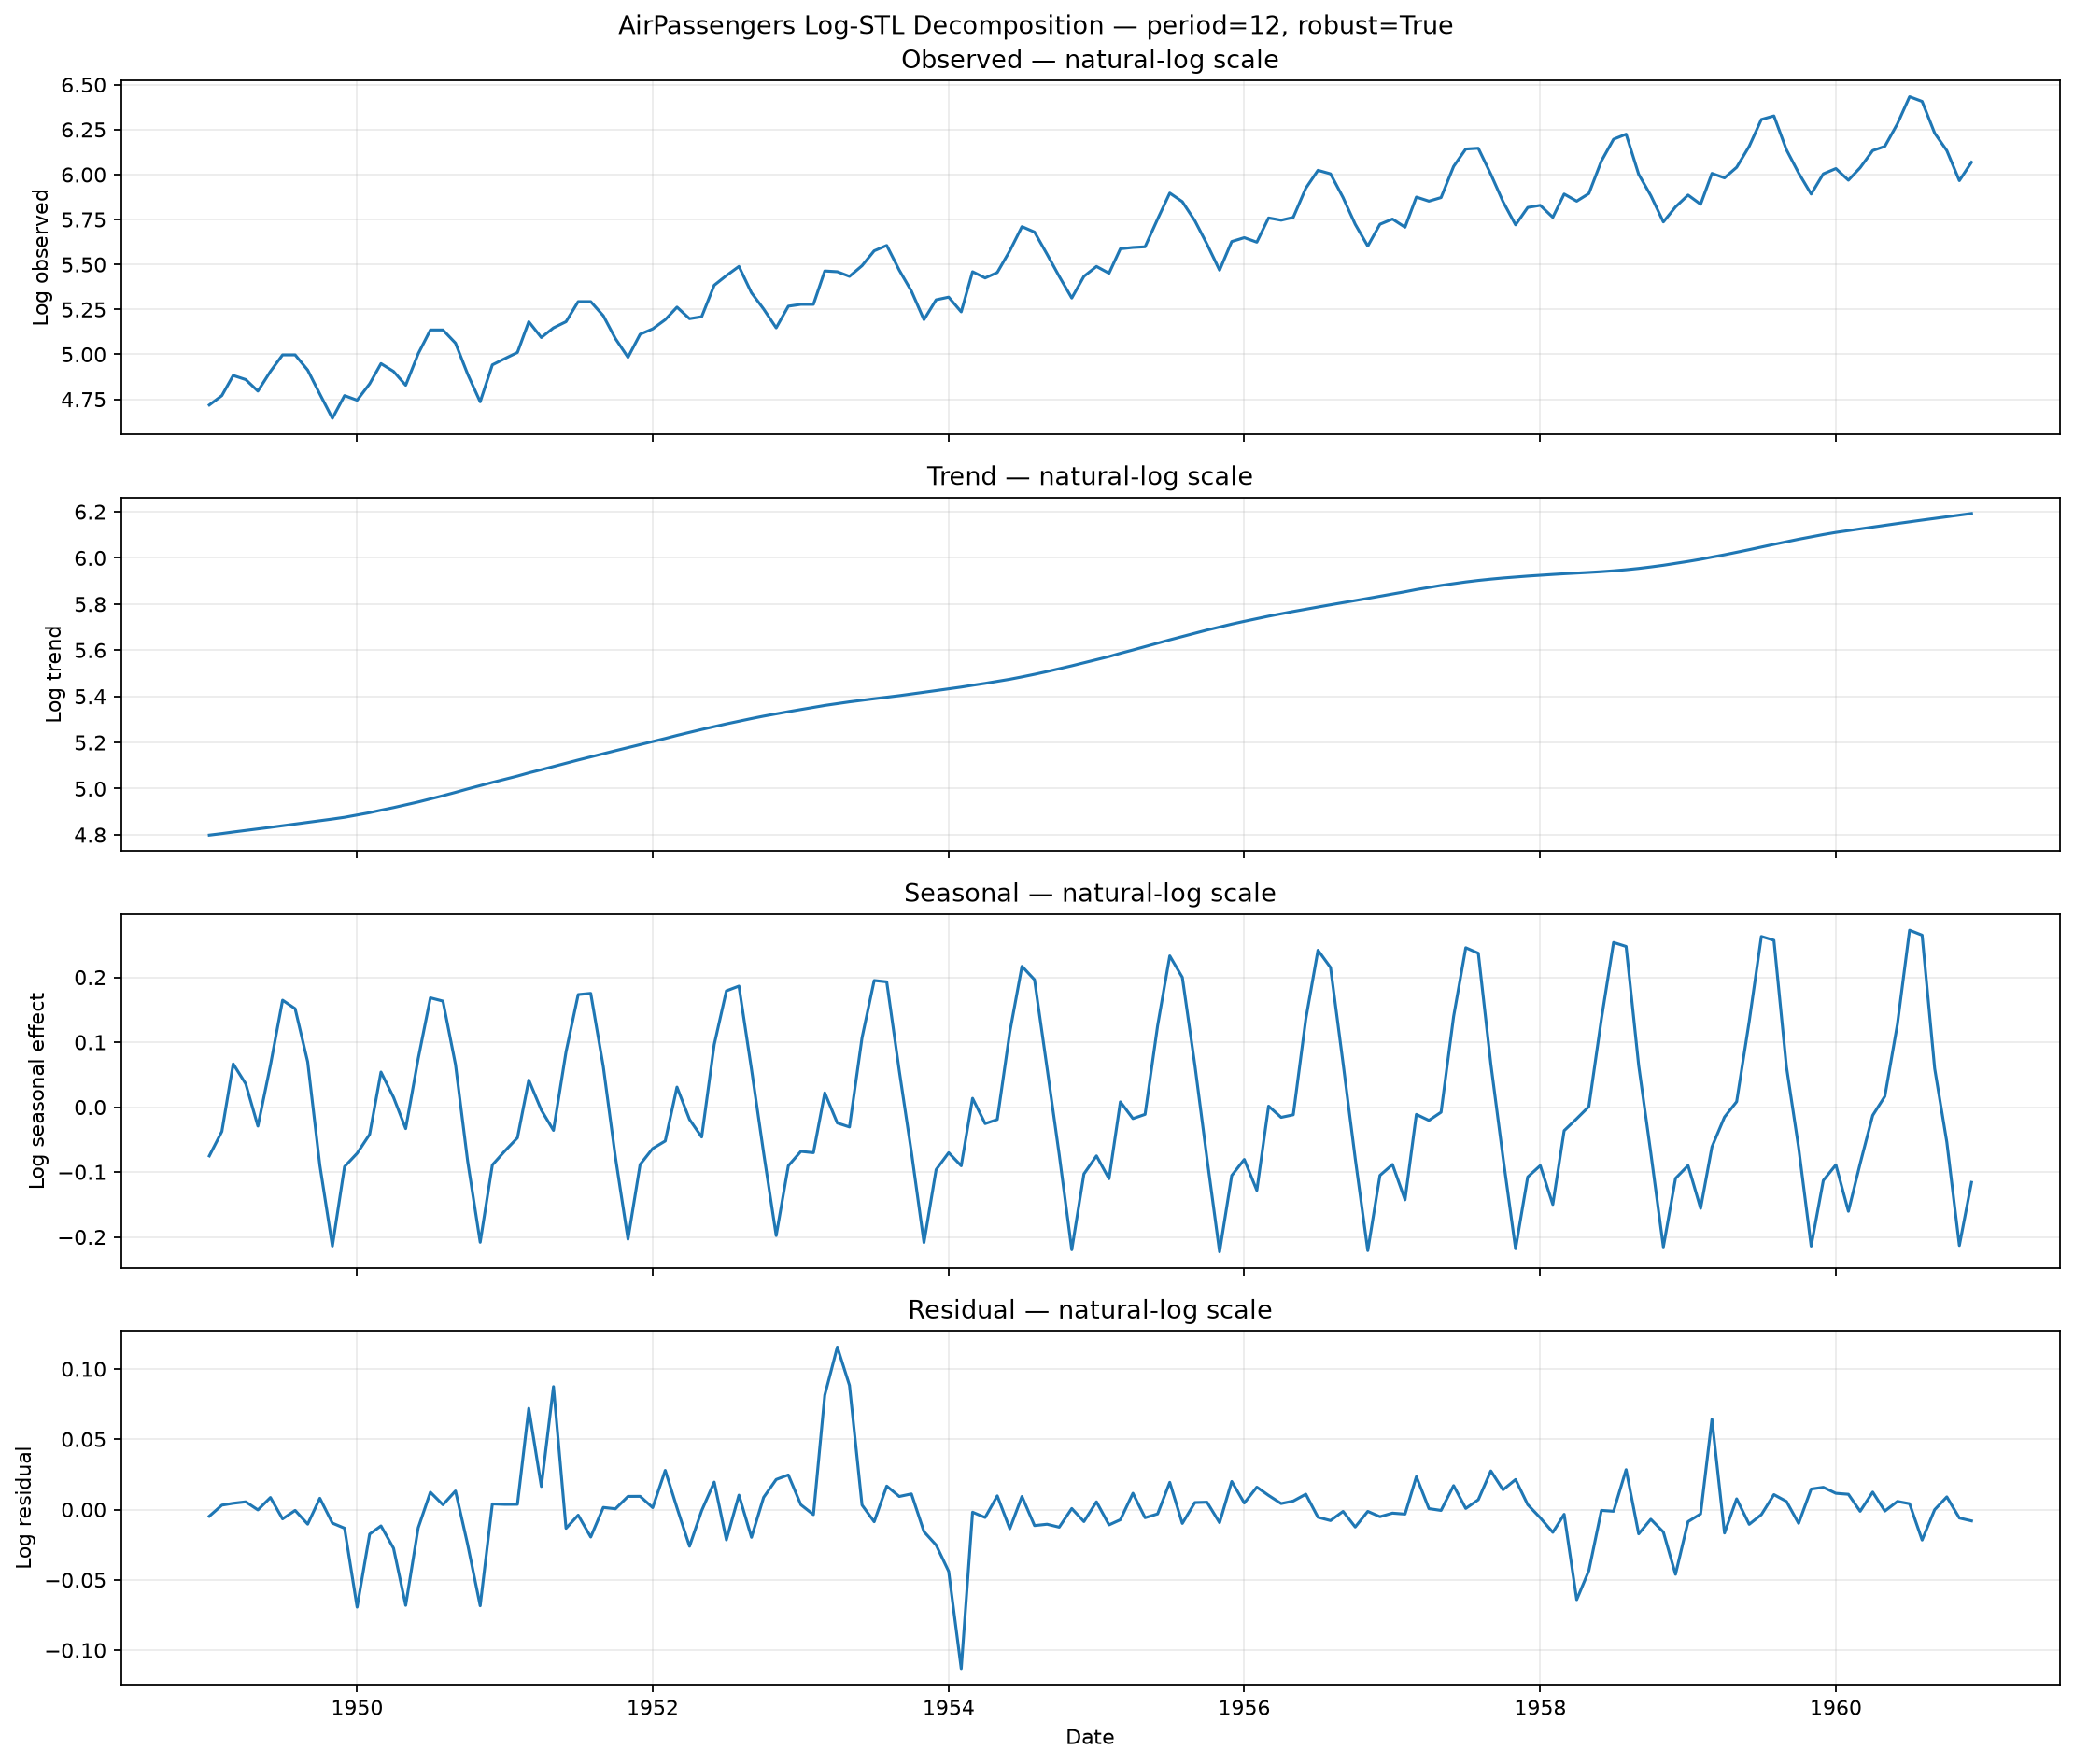

số_quan_sát,tất_cả_giá_trị_dương,giá_trị_thiếu,tần_suất,STL_period,STL_robust,sai_số_tái_tạo_lớn_nhất
144,True,0,MS,12,True,0.0000


In [16]:
from practice_1.analysis import (
    compute_residual_diagnostics,
    compute_stl_decomposition,
    log_transform_series,
    validate_decomposition_series,
)
from practice_1.visualization import (
    plot_decomposition_residual_diagnostics,
    plot_log_transformed_series,
    plot_stl_decomposition,
)

DECOMPOSITION_PERIOD = 12
DECOMPOSITION_ROBUST = True
RESIDUAL_MAX_LAG = 40
LJUNG_BOX_LAG = 12

validated_series = validate_decomposition_series(series)
if not validated_series.equals(series):
    raise ValueError("Validated E1 series changed before decomposition")

log_series = log_transform_series(validated_series)
decomposition_components = compute_stl_decomposition(
    log_series,
    period=DECOMPOSITION_PERIOD,
    robust=DECOMPOSITION_ROBUST,
)
reconstructed_log = (
    decomposition_components["trend_log"]
    + decomposition_components["seasonal_log"]
    + decomposition_components["residual_log"]
)
reconstruction_error = float(
    (decomposition_components["observed_log"] - reconstructed_log)
    .abs()
    .max()
)

log_series_figure = FIGURES_DIR / "07_log_transformed_series.png"
decomposition_figure = FIGURES_DIR / "08_stl_decomposition.png"
plot_log_transformed_series(log_series, log_series_figure)
plot_stl_decomposition(decomposition_components, decomposition_figure)
display(Image(filename=str(log_series_figure)))
display(Image(filename=str(decomposition_figure)))

decomposition_validation = pd.DataFrame(
    {
        "số_quan_sát": [len(validated_series)],
        "tất_cả_giá_trị_dương": [bool(validated_series.gt(0).all())],
        "giá_trị_thiếu": [int(validated_series.isna().sum())],
        "tần_suất": [validated_series.index.freqstr],
        "STL_period": [DECOMPOSITION_PERIOD],
        "STL_robust": [DECOMPOSITION_ROBUST],
        "sai_số_tái_tạo_lớn_nhất": [reconstruction_error],
    }
)
display(
    visualise_table(
        decomposition_validation,
        "Kiểm tra đầu vào và cấu hình phân rã STL",
    ).map(
        boolean_cell_color,
        subset=["tất_cả_giá_trị_dương", "STL_robust"],
    )
)

### Bằng chứng cần đọc trước khi kết luận

Các component bên dưới đều nằm trên **thang log tự nhiên**. Phần residual được
đánh giá bằng ba nguồn bằng chứng: diễn biến theo thời gian, ACF đến 40 lag với
khoảng tin cậy 95% và kiểm định Ljung–Box tại lag 12. Ljung–Box chỉ là bằng chứng
bổ sung, không thay thế việc đọc biểu đồ và ACF.

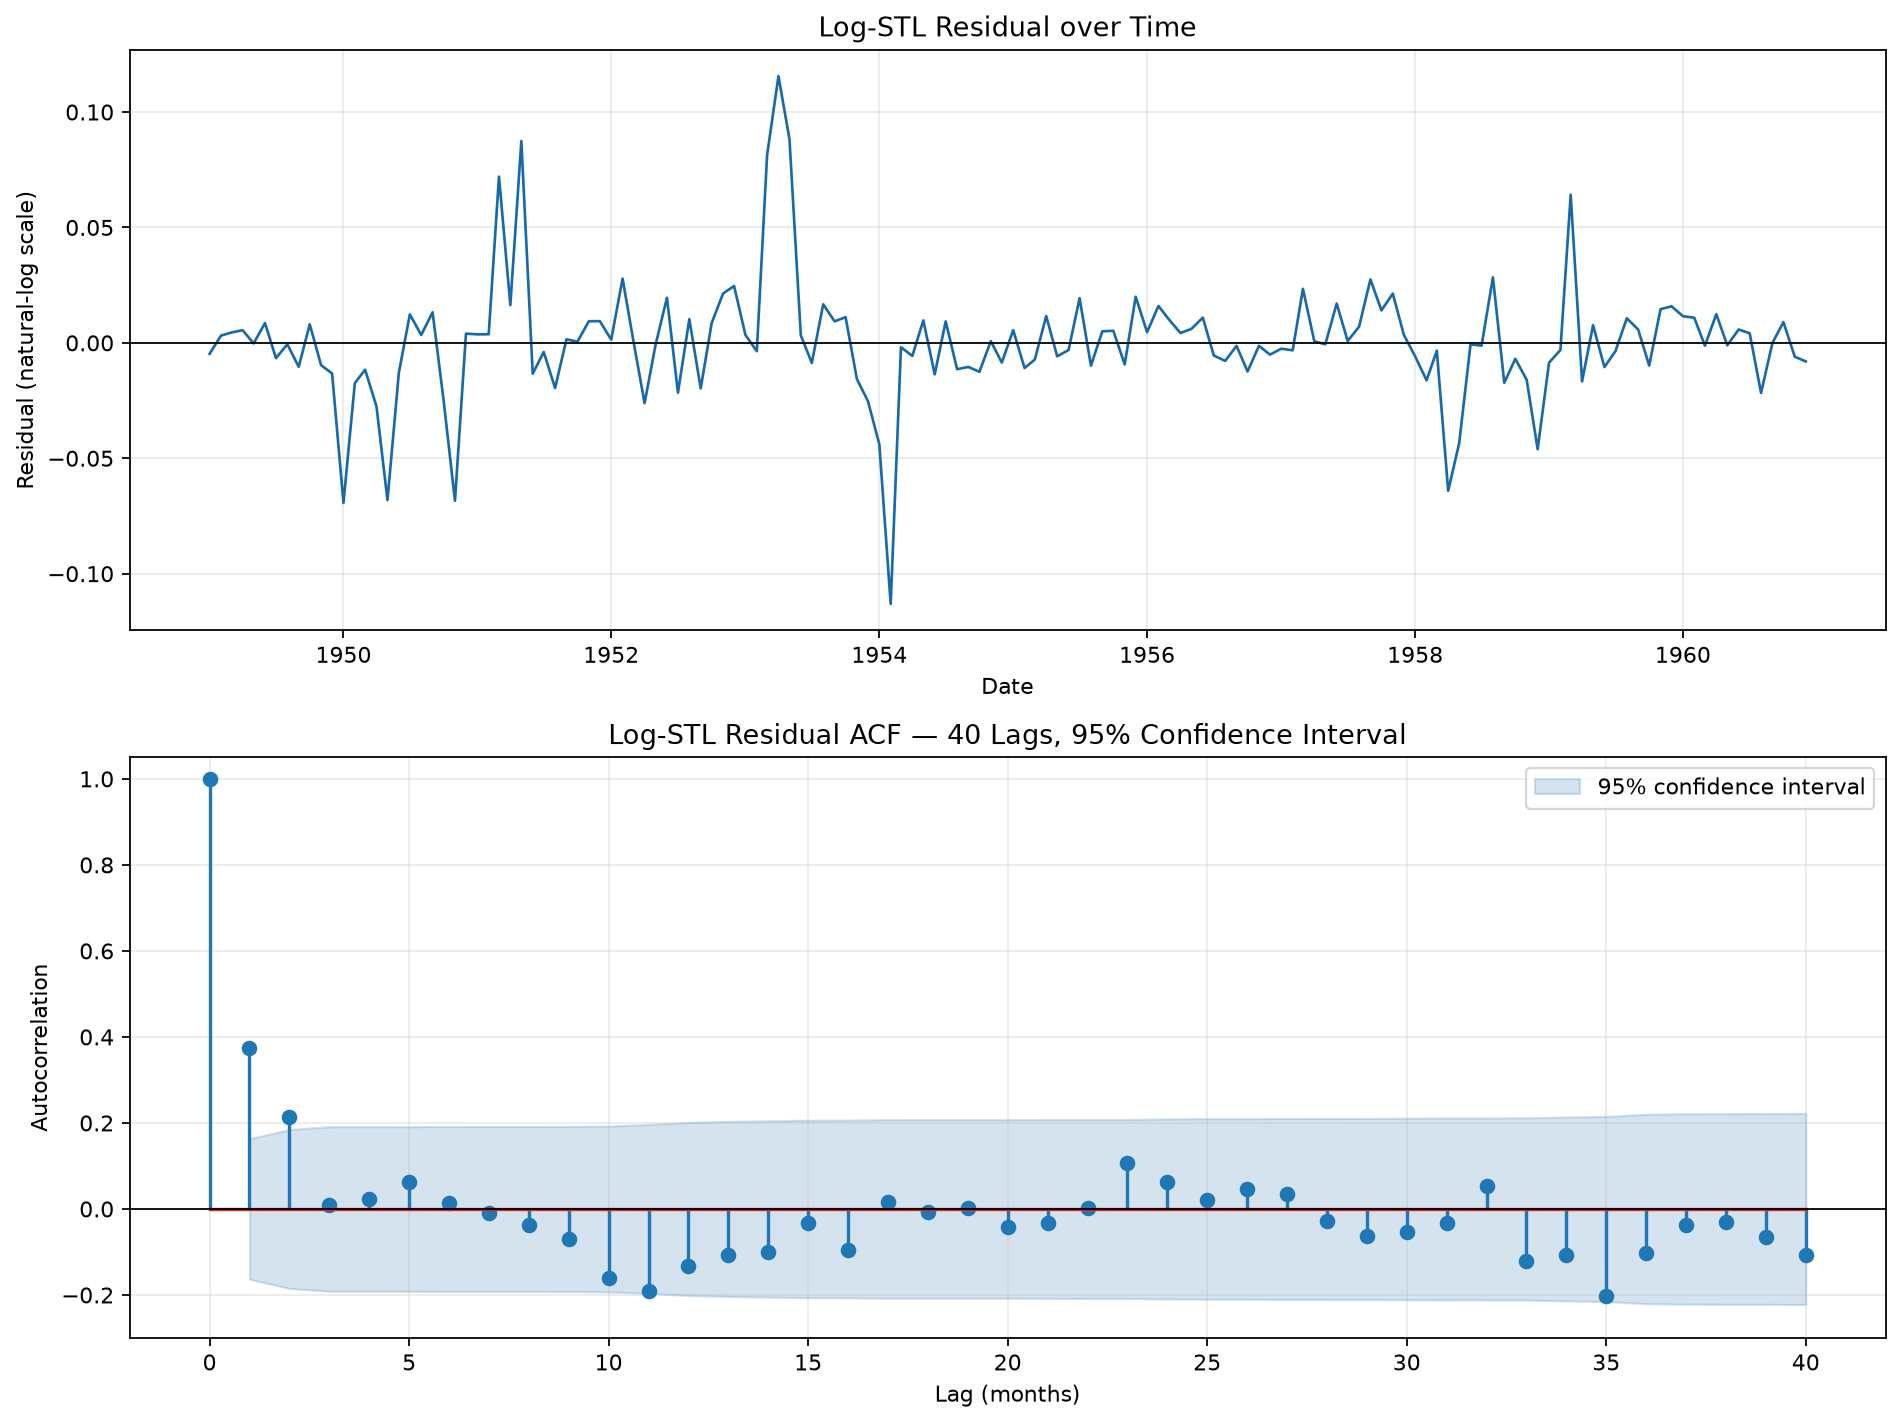

lag,ljung_box_statistic,p_value
12,41.7094,0.0000


trung_bình_residual_log,độ_lệch_chuẩn_mẫu,ACF_lag_1,ACF_lag_12,các_lag_vượt_CI_95%,residual_tuyệt_đối_lớn_nhất_tại,giá_trị_residual
0.0003,0.0265,0.3747,-0.1336,"[1, 2]",1953-04-01 00:00:00,0.1156


In [17]:
components_output = RESULTS_DIR / "decomposition_components.csv"
decomposition_components.reset_index().to_csv(components_output, index=False)

residual = decomposition_components["residual_log"]
residual_acf_table, residual_diagnostics = compute_residual_diagnostics(
    residual,
    max_lag=RESIDUAL_MAX_LAG,
    alpha=ALPHA,
    ljung_box_lag=LJUNG_BOX_LAG,
)
residual_diagnostics.to_csv(
    RESULTS_DIR / "residual_diagnostics.csv",
    index=False,
)

residual_significant_lags = (
    residual_acf_table.loc[
        residual_acf_table["lag"].ne(0)
        & (
            (residual_acf_table["lower_ci"] > 0)
            | (residual_acf_table["upper_ci"] < 0)
        ),
        "lag",
    ]
    .astype(int)
    .tolist()
)
largest_residual_timestamp = residual.abs().idxmax()
largest_residual_value = float(residual.loc[largest_residual_timestamp])

residual_figure = FIGURES_DIR / "09_decomposition_residual.png"
plot_decomposition_residual_diagnostics(
    residual,
    residual_acf_table,
    residual_figure,
)
display(Image(filename=str(residual_figure)))
display(visualise_table(
    residual_diagnostics,
    "Kiểm định Ljung–Box cho residual",
    gradient_columns=["ljung_box_statistic", "p_value"],
))

residual_summary = pd.DataFrame(
    {
        "trung_bình_residual_log": [residual.mean()],
        "độ_lệch_chuẩn_mẫu": [residual.std(ddof=1)],
        "ACF_lag_1": [residual_acf_table.loc[1, "acf"]],
        "ACF_lag_12": [residual_acf_table.loc[12, "acf"]],
        "các_lag_vượt_CI_95%": [residual_significant_lags],
        "residual_tuyệt_đối_lớn_nhất_tại": [largest_residual_timestamp],
        "giá_trị_residual": [largest_residual_value],
    }
)
display(visualise_table(
    residual_summary,
    "Tóm tắt chẩn đoán residual sau phân rã",
))

In [18]:
trend = decomposition_components["trend_log"]
seasonal = decomposition_components["seasonal_log"]
seasonal_lag_12_correlation = float(seasonal.autocorr(lag=12))
seasonal_strength = max(
    0.0,
    1.0 - float(residual.var(ddof=1) / (seasonal + residual).var(ddof=1)),
)
ljung_box_statistic = float(residual_diagnostics.loc[0, "ljung_box_statistic"])
ljung_box_p_value = float(residual_diagnostics.loc[0, "p_value"])
significant_lags_text = ", ".join(map(str, residual_significant_lags))

decomposition_markdown = chr(10).join(
    [
        "## Phân tích kết quả Exercise 3",
        "",
        f"1. **Xu hướng tăng hay giảm?** Trend trên thang log tăng từ **{trend.iloc[0]:.4f}** lên **{trend.iloc[-1]:.4f}**, vì vậy AirPassengers có xu hướng dài hạn tăng.",
        "",
        f"2. **Mùa vụ mạnh hay yếu?** Mùa vụ mạnh, với seasonal strength khoảng **{seasonal_strength:.4f}** và tương quan seasonal component tại lag 12 khoảng **{seasonal_lag_12_correlation:.4f}**; pattern lặp lại rõ theo chu kỳ hằng năm.",
        "",
        f"3. **Residual có giống white noise không?** Chưa hoàn toàn. Residual dao động quanh 0 với trung bình **{residual.mean():.6f}**, nhưng ACF còn vượt khoảng tin cậy tại lag **{significant_lags_text}**. Kiểm định Ljung–Box tại lag 12 cho statistic **{ljung_box_statistic:.4f}** và p-value **{ljung_box_p_value:.6f}**, nên bác bỏ giả thuyết residual là white noise ở mức ý nghĩa 5%.",
    ]
)

display(Markdown(decomposition_markdown))

## Phân tích kết quả Exercise 3

1. **Xu hướng tăng hay giảm?** Trend trên thang log tăng từ **4.7985** lên **6.1925**, vì vậy AirPassengers có xu hướng dài hạn tăng.

2. **Mùa vụ mạnh hay yếu?** Mùa vụ mạnh, với seasonal strength khoảng **0.9593** và tương quan seasonal component tại lag 12 khoảng **0.9978**; pattern lặp lại rõ theo chu kỳ hằng năm.

3. **Residual có giống white noise không?** Chưa hoàn toàn. Residual dao động quanh 0 với trung bình **0.000290**, nhưng ACF còn vượt khoảng tin cậy tại lag **1, 2**. Kiểm định Ljung–Box tại lag 12 cho statistic **41.7094** và p-value **0.000037**, nên bác bỏ giả thuyết residual là white noise ở mức ý nghĩa 5%.

## Exercise 4 — Chất lượng dữ liệu chuỗi thời gian

Thí nghiệm dùng sáu timestamp đã khóa để so sánh forward-fill với time interpolation, sau đó flag potential outliers trên log-STL residual.

In [19]:
from practice_1.analysis import (
    apply_missing_value_treatments,
    build_missing_value_comparison,
    detect_residual_iqr_outliers,
    simulate_missing_values,
    summarize_reconstruction_mae,
)
from practice_1.visualization import (
    plot_missing_treatment_comparison,
    plot_missing_values_simulation,
    plot_residual_outlier_analysis,
)

LOCKED_MISSING_TIMESTAMPS = (
    "1952-03-01", "1954-11-01", "1959-04-01",
    "1956-06-01", "1956-07-01", "1956-08-01",
)
OUTLIER_IQR_MULTIPLIER = 1.5
original_series = validate_decomposition_series(series)
original_missing_count = int(original_series.isna().sum())
if original_missing_count != 0:
    raise ValueError("Validated AirPassengers series unexpectedly contains missing values")


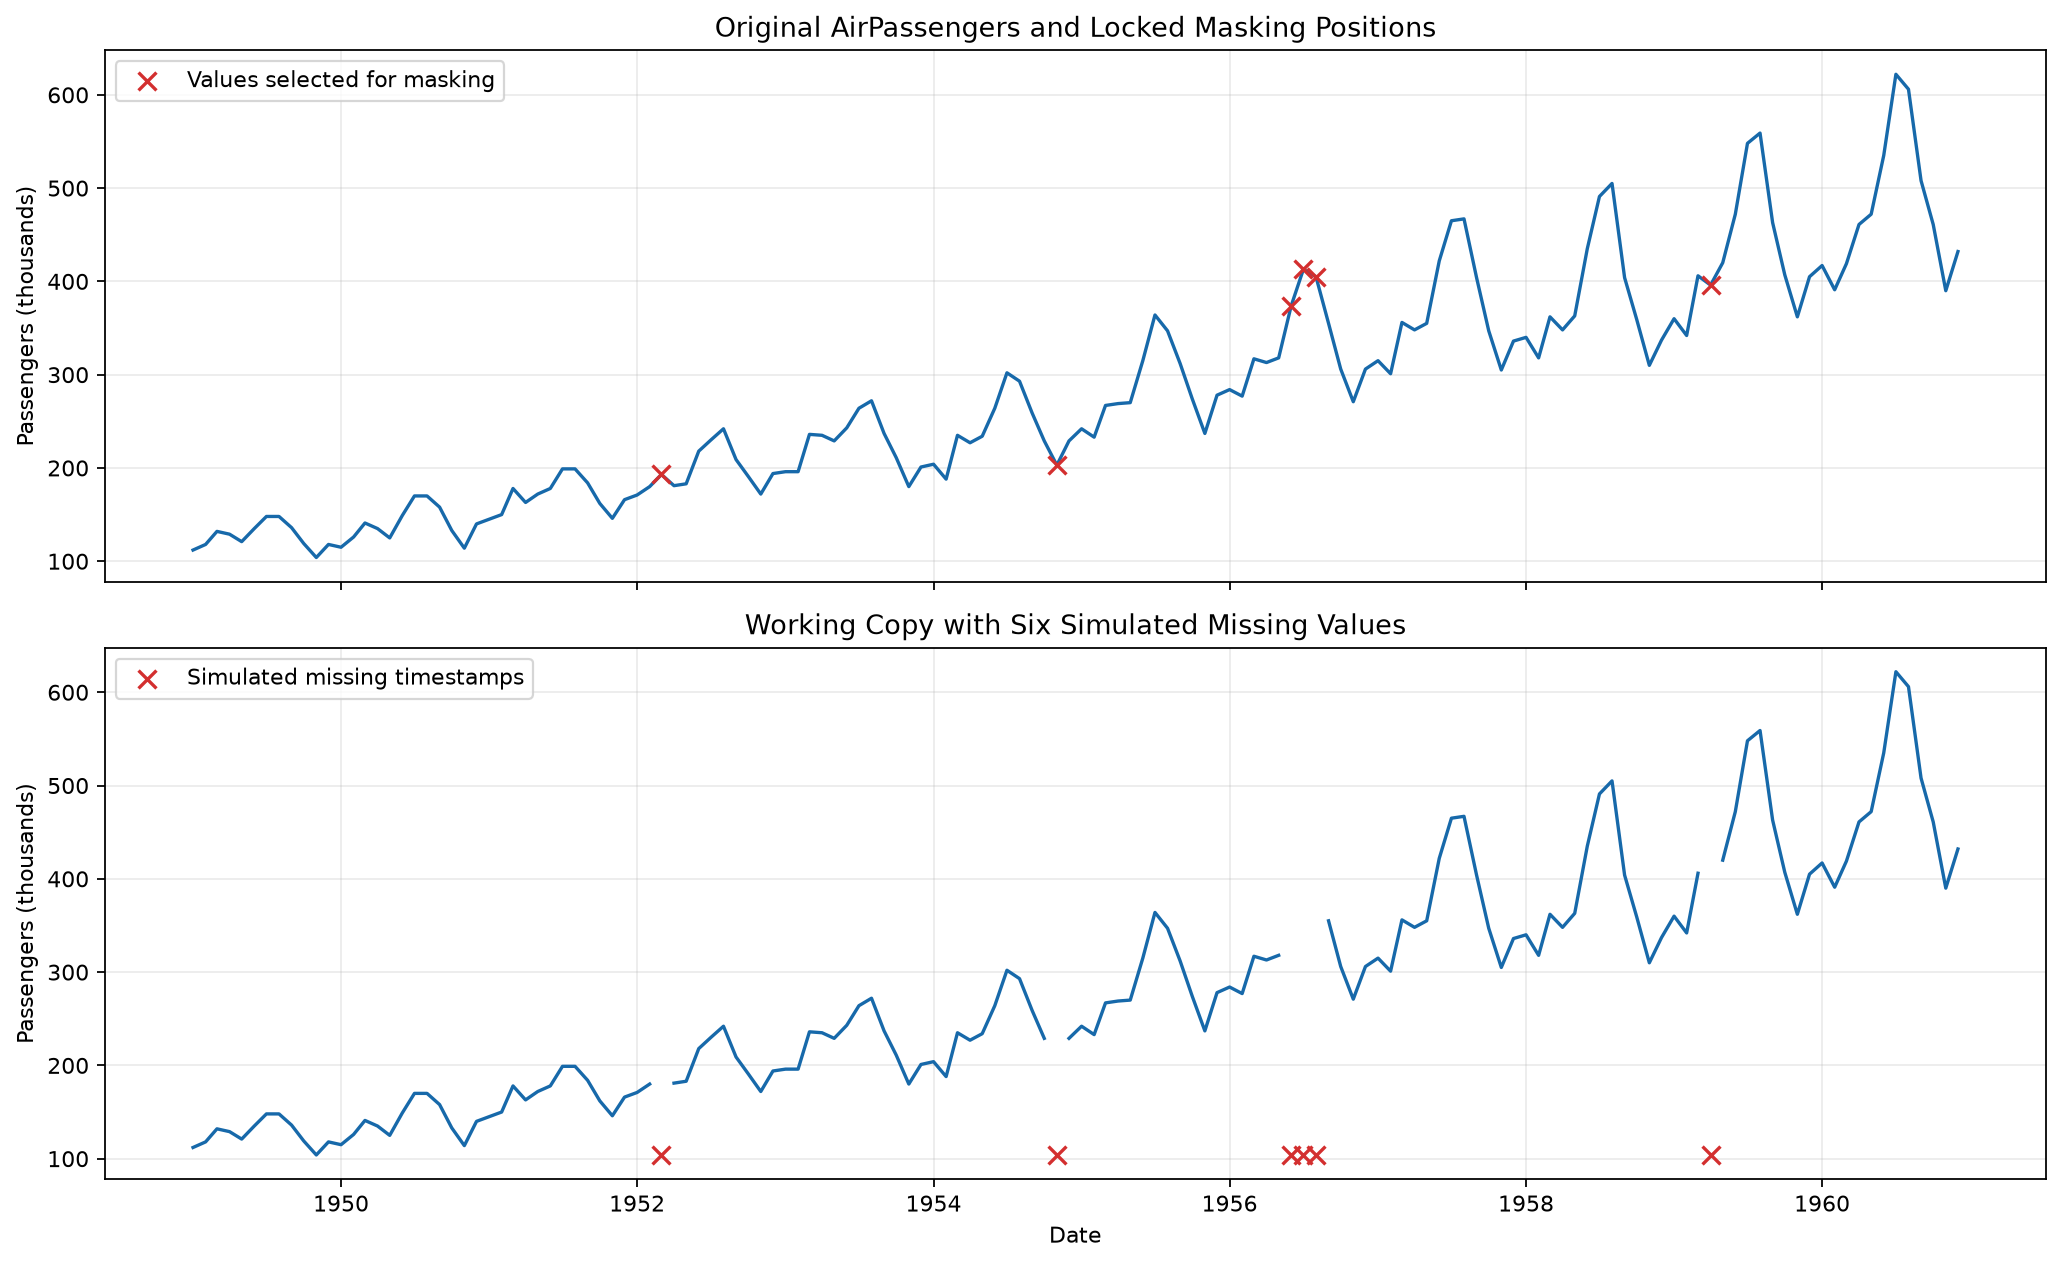

missing_ban_đầu,missing_giả_lập,timestamp_được_mask
0,6,"1952-03, 1954-11, 1956-06, 1956-07, 1956-08, 1959-04"


In [20]:
masked_series, ground_truth = simulate_missing_values(
    original_series, LOCKED_MISSING_TIMESTAMPS
)
masked_timestamps = ground_truth.index
if masked_series.isna().sum() != len(LOCKED_MISSING_TIMESTAMPS):
    raise ValueError("Simulated missing count does not match the locked protocol")

missing_simulation_figure = FIGURES_DIR / "10_missing_values_simulation.png"
plot_missing_values_simulation(
    original_series, masked_series, masked_timestamps, missing_simulation_figure
)
display(Image(filename=str(missing_simulation_figure)))
missing_simulation_summary = pd.DataFrame({
    "missing_ban_đầu": [original_missing_count],
    "missing_giả_lập": [int(masked_series.isna().sum())],
    "timestamp_được_mask": [", ".join(masked_timestamps.strftime("%Y-%m"))],
})
display(visualise_table(
    missing_simulation_summary,
    "Tóm tắt dữ liệu thiếu được mô phỏng",
))


In [21]:
forward_fill_series, interpolation_series = apply_missing_value_treatments(
    masked_series
)
unmasked_positions = ~original_series.index.isin(masked_timestamps)
if not np.array_equal(
    forward_fill_series.loc[unmasked_positions].to_numpy(),
    original_series.loc[unmasked_positions].to_numpy(),
):
    raise ValueError("Forward-fill changed observations outside masked positions")
if not np.array_equal(
    interpolation_series.loc[unmasked_positions].to_numpy(),
    original_series.loc[unmasked_positions].to_numpy(),
):
    raise ValueError("Time interpolation changed observations outside masked positions")

missing_treatment_summary = pd.DataFrame({
    "method": ["forward_fill", "time_interpolation"],
    "missing_sau_xử_lý": [
        int(forward_fill_series.isna().sum()),
        int(interpolation_series.isna().sum()),
    ],
    "interpolation_method": ["not_applicable", "time"],
    "limit_area": ["not_applicable", "inside"],
})
display(visualise_table(
    missing_treatment_summary,
    "Kết quả xử lý missing theo từng phương pháp",
))


method,missing_sau_xử_lý,interpolation_method,limit_area
forward_fill,0,not_applicable,not_applicable
time_interpolation,0,time,inside


In [22]:
missing_value_comparison = build_missing_value_comparison(
    ground_truth, forward_fill_series, interpolation_series
)
reconstruction_mae = summarize_reconstruction_mae(missing_value_comparison)
missing_value_comparison.to_csv(
    RESULTS_DIR / "missing_value_comparison.csv", index=False
)
forward_fill_mae = float(
    reconstruction_mae.loc[
        reconstruction_mae["method"].eq("forward_fill"), "mae_masked_positions"
    ].iloc[0]
)
interpolation_mae = float(
    reconstruction_mae.loc[
        reconstruction_mae["method"].eq("time_interpolation"),
        "mae_masked_positions",
    ].iloc[0]
)
display(
    visualise_table(
        missing_value_comparison,
        "So sánh giá trị khôi phục tại sáu timestamp bị che",
    ).highlight_min(
        axis=1,
        subset=["forward_fill_absolute_error", "interpolation_absolute_error"],
        props="background-color: #86efac; color: #14532d; font-weight: 700;",
    )
)
display(
    visualise_table(
        reconstruction_mae,
        "MAE tái tạo trên các vị trí bị che",
    ).highlight_min(
        axis=0,
        subset=["mae_masked_positions"],
        props="background-color: #86efac; color: #14532d; font-weight: 700;",
    )
)


timestamp,true_value,forward_fill_value,interpolation_value,forward_fill_absolute_error,interpolation_absolute_error
1952-03-01 00:00:00,193.0000,180.0000,180.4833,13.0000,12.5167
1954-11-01 00:00:00,203.0000,229.0000,229.0000,26.0000,26.0000
1956-06-01 00:00:00,374.0000,318.0000,327.3252,56.0000,46.6748
1956-07-01 00:00:00,413.0000,318.0000,336.3496,95.0000,76.6504
1956-08-01 00:00:00,405.0000,318.0000,345.6748,87.0000,59.3252
1959-04-01 00:00:00,396.0000,406.0000,413.1148,10.0000,17.1148


method,mae_masked_positions
forward_fill,47.8333
time_interpolation,39.7136


### Hai phương pháp reconstruction

- **Forward-fill** dùng quan sát hợp lệ gần nhất trong quá khứ. Phương pháp không dùng
  future value nhưng có thể tạo plateau khi nhiều tháng liên tiếp bị thiếu.
- **Time interpolation** dùng khoảng cách timestamp và các quan sát ở hai phía với
  method time và limit_area inside; đường tái tạo thường trơn hơn.


### Giới hạn diễn giải

Time interpolation trong E4 là thí nghiệm **data reconstruction** có ground truth.
Vì phương pháp có thể dùng thông tin sau timestamp bị thiếu, kết quả này không chứng
minh rằng interpolation mặc định an toàn cho forecasting thời gian thực.


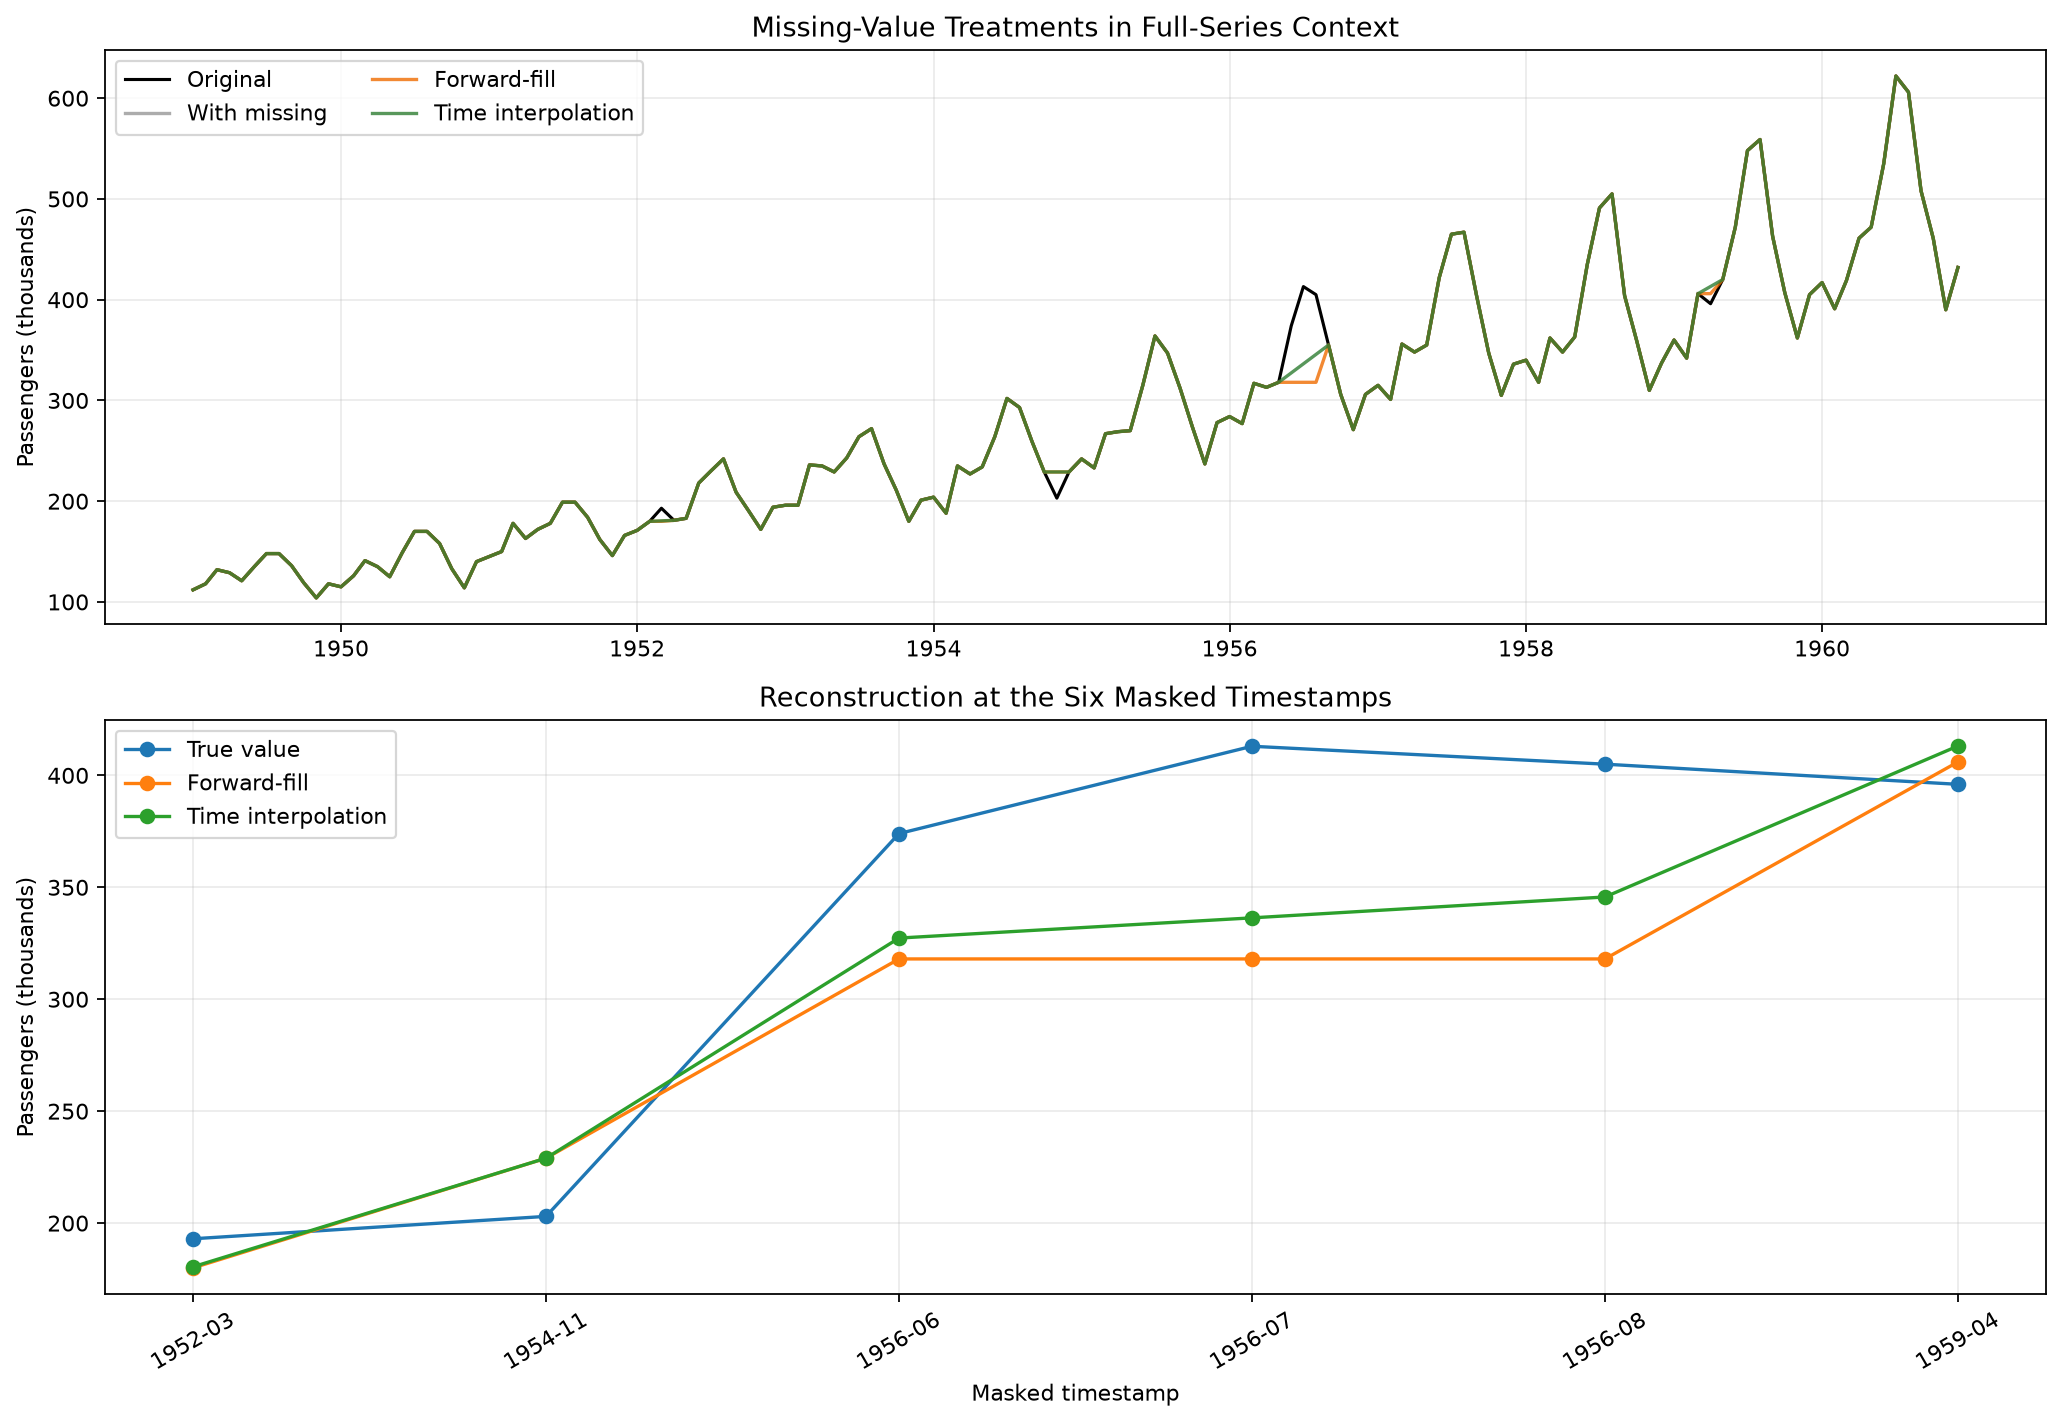

In [23]:
missing_treatment_figure = FIGURES_DIR / "11_missing_treatment_comparison.png"
plot_missing_treatment_comparison(
    original_series,
    masked_series,
    forward_fill_series,
    interpolation_series,
    missing_value_comparison,
    missing_treatment_figure,
)
display(Image(filename=str(missing_treatment_figure)))


In [24]:
e3_components = pd.read_csv(
    RESULTS_DIR / "decomposition_components.csv", parse_dates=["timestamp"]
).set_index("timestamp")
expected_component_columns = [
    "observed_log", "trend_log", "seasonal_log", "residual_log"
]
if e3_components.columns.tolist() != expected_component_columns:
    raise ValueError("Validated E3 component output has an unexpected schema")
if not e3_components.index.equals(original_series.index):
    raise ValueError("E3 component timestamps do not align with AirPassengers")
if not np.allclose(
    e3_components["residual_log"].to_numpy(),
    decomposition_components["residual_log"].to_numpy(),
):
    raise ValueError("E3 residual CSV does not match the executed E3 result")

residual_log = pd.Series(
    e3_components["residual_log"].to_numpy(),
    index=original_series.index,
    name="residual_log",
)
outlier_candidates, iqr_thresholds = detect_residual_iqr_outliers(
    original_series, residual_log, multiplier=OUTLIER_IQR_MULTIPLIER
)


### IQR trên log-STL residual

E4 không áp dụng IQR trực tiếp lên passenger counts vì trend và seasonal peaks có thể
bị hiểu nhầm là outlier. Protocol dùng residual trên natural-log scale từ E3:

\[
IQR = Q_3 - Q_1
\]

\[
Lower = Q_1 - 1.5\,IQR, \qquad Upper = Q_3 + 1.5\,IQR
\]


Các điểm nằm ngoài IQR fences chỉ được gắn nhãn **potential outlier candidate**.
E4 đối chiếu chúng với timestamp, observed value và residual; không clipping, không
xóa và không thay thế bất kỳ observation nào.


In [25]:
outlier_candidates.to_csv(
    RESULTS_DIR / "outlier_candidates.csv", index=False
)
outlier_summary = pd.DataFrame({
    "q1": [iqr_thresholds["q1"]],
    "q3": [iqr_thresholds["q3"]],
    "iqr": [iqr_thresholds["iqr"]],
    "lower_fence": [iqr_thresholds["lower_fence"]],
    "upper_fence": [iqr_thresholds["upper_fence"]],
    "số_candidate": [len(outlier_candidates)],
    "action": ["flag_and_inspect_only"],
})
display(visualise_table(
    outlier_summary,
    "Ngưỡng IQR và số potential outlier candidates",
))
residual_limit = float(outlier_candidates["residual_log"].abs().max())
display(
    visualise_table(
        outlier_candidates,
        "Danh sách potential outlier candidates trên log-STL residual",
    )
    .background_gradient(
        cmap="coolwarm",
        subset=["residual_log"],
        axis=None,
        vmin=-residual_limit,
        vmax=residual_limit,
    )
    .map(
        lambda value: boolean_cell_color(value, alert=True),
        subset=["flag"],
    )
)


q1,q3,iqr,lower_fence,upper_fence,số_candidate,action
-0.0097,0.0094,0.0191,-0.0383,0.0380,14,flag_and_inspect_only


timestamp,observed_value,residual_log,q1,q3,iqr,lower_fence,upper_fence,flag
1950-01-01 00:00:00,115.0000,-0.0694,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1950-05-01 00:00:00,125.0000,-0.0681,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1950-11-01 00:00:00,114.0000,-0.0684,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1951-03-01 00:00:00,178.0000,0.0720,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1951-05-01 00:00:00,172.0000,0.0874,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1953-03-01 00:00:00,236.0000,0.0813,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1953-04-01 00:00:00,235.0000,0.1156,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1953-05-01 00:00:00,229.0000,0.0883,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1954-01-01 00:00:00,204.0000,-0.0440,-0.0097,0.0094,0.0191,-0.0383,0.0380,True
1954-02-01 00:00:00,188.0000,-0.1131,-0.0097,0.0094,0.0191,-0.0383,0.0380,True


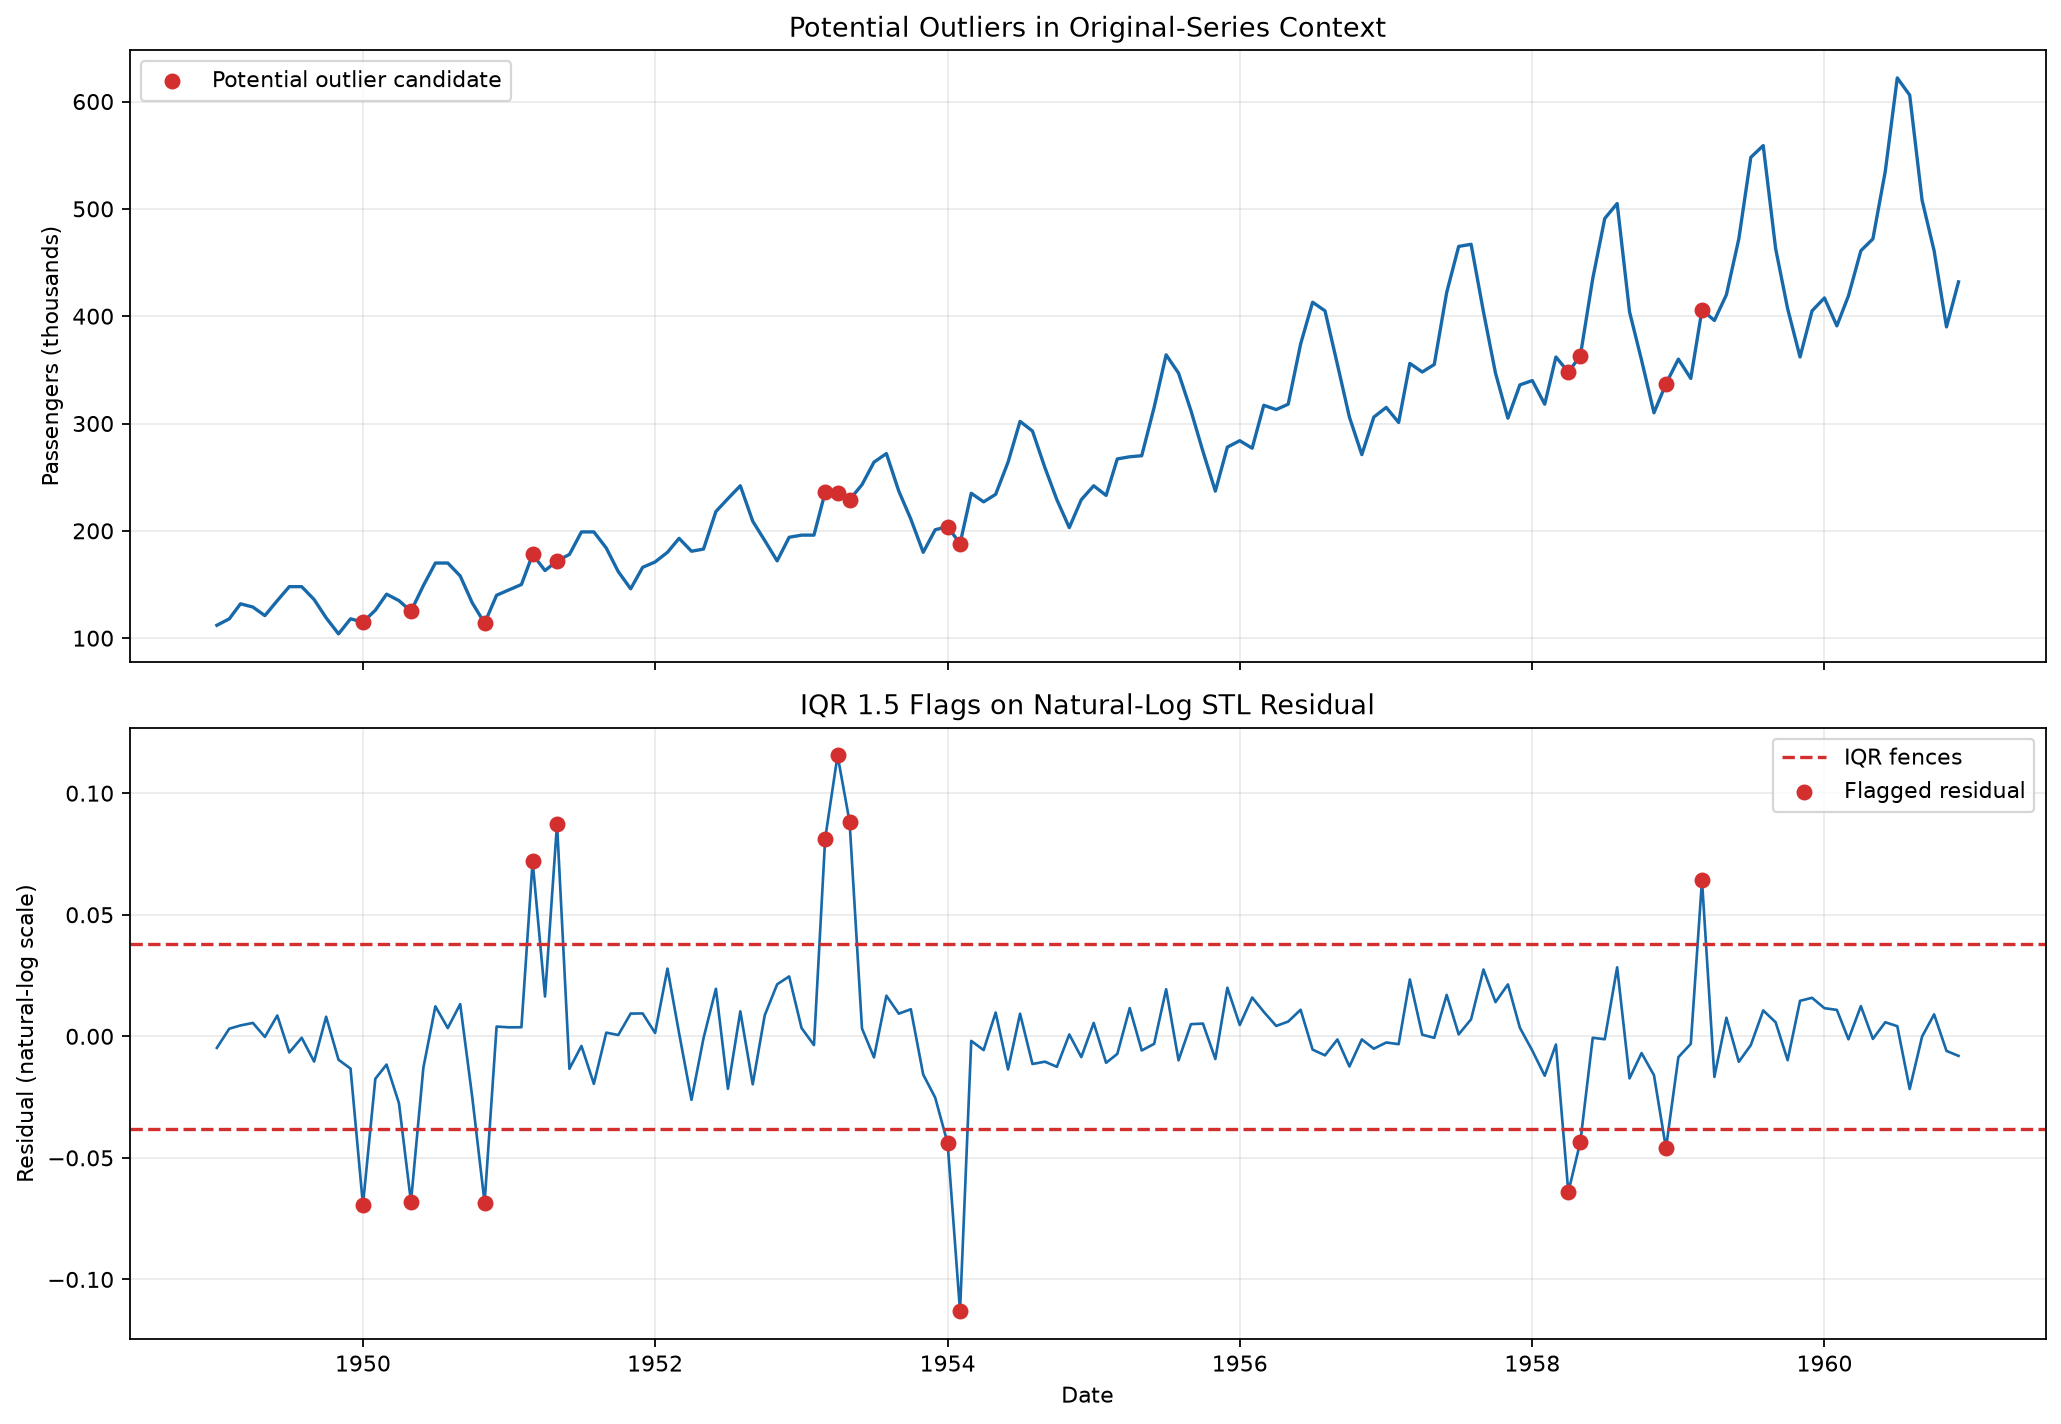

In [26]:
outlier_figure = FIGURES_DIR / "12_outlier_analysis.png"
plot_residual_outlier_analysis(
    original_series,
    residual_log,
    outlier_candidates,
    lower_fence=iqr_thresholds["lower_fence"],
    upper_fence=iqr_thresholds["upper_fence"],
    output_path=outlier_figure,
)
display(Image(filename=str(outlier_figure)))


In [27]:
data_quality_markdown = chr(10).join([
    "## Phân tích kết quả Exercise 4",
    "",
    f"1. **Tạo dữ liệu thiếu:** Dataset gốc có **{original_missing_count}** missing; E4 tạo **{len(masked_timestamps)}** giá trị `NaN` trên bản sao tại {', '.join(masked_timestamps.strftime('%Y-%m'))}, không thay đổi raw data.",
    "",
    f"2. **Kiểm tra missing:** Sau mô phỏng có **{int(masked_series.isna().sum())}** missing; sau forward-fill và time interpolation, mỗi chuỗi còn lần lượt **{int(forward_fill_series.isna().sum())}** và **{int(interpolation_series.isna().sum())}** missing.",
    "",
    f"3. **Xử lý bằng hai phương pháp:** Forward-fill dùng giá trị hợp lệ gần nhất nên tạo plateau ở block 1956-06 đến 1956-08. Time interpolation dùng hai phía và tạo chuyển tiếp trơn hơn; MAE là **{interpolation_mae:.4f}**, thấp hơn **{forward_fill_mae:.4f}** của forward-fill trên sáu vị trí bị che.",
    "",
    f"4. **Phát hiện outlier:** IQR 1.5 trên log-STL residual flag **{len(outlier_candidates)}** potential candidates. Đây chưa phải anomaly đã xác nhận; E4 chỉ flag để kiểm tra, không tự động xóa, clip hoặc thay thế.",
    "",
    "5. **Trước và sau xử lý:** Các biểu đồ cho thấy cả hai phương pháp đều lấp đầy toàn bộ missing. Interpolation nhìn chung bám ground truth tốt hơn, nhưng kết quả reconstruction này có sử dụng thông tin ở hai phía và không mặc nhiên an toàn cho forecasting thời gian thực.",
])
display(Markdown(data_quality_markdown))


## Phân tích kết quả Exercise 4

1. **Tạo dữ liệu thiếu:** Dataset gốc có **0** missing; E4 tạo **6** giá trị `NaN` trên bản sao tại 1952-03, 1954-11, 1956-06, 1956-07, 1956-08, 1959-04, không thay đổi raw data.

2. **Kiểm tra missing:** Sau mô phỏng có **6** missing; sau forward-fill và time interpolation, mỗi chuỗi còn lần lượt **0** và **0** missing.

3. **Xử lý bằng hai phương pháp:** Forward-fill dùng giá trị hợp lệ gần nhất nên tạo plateau ở block 1956-06 đến 1956-08. Time interpolation dùng hai phía và tạo chuyển tiếp trơn hơn; MAE là **39.7136**, thấp hơn **47.8333** của forward-fill trên sáu vị trí bị che.

4. **Phát hiện outlier:** IQR 1.5 trên log-STL residual flag **14** potential candidates. Đây chưa phải anomaly đã xác nhận; E4 chỉ flag để kiểm tra, không tự động xóa, clip hoặc thay thế.

5. **Trước và sau xử lý:** Các biểu đồ cho thấy cả hai phương pháp đều lấp đầy toàn bộ missing. Interpolation nhìn chung bám ground truth tốt hơn, nhưng kết quả reconstruction này có sử dụng thông tin ở hai phía và không mặc nhiên an toàn cho forecasting thời gian thực.

# Exercise 5 — Trực quan hóa chuỗi thời gian

E5 tổng hợp evidence trực quan cuối cùng từ chuỗi AirPassengers đã được xác minh. Phần này dùng trailing rolling window 12 tháng, seasonal plot theo tháng, heatmap tháng–năm và đối chiếu trực tiếp với kết quả E1, E3 và E4. Không huấn luyện forecasting model và không thay đổi dữ liệu gốc.

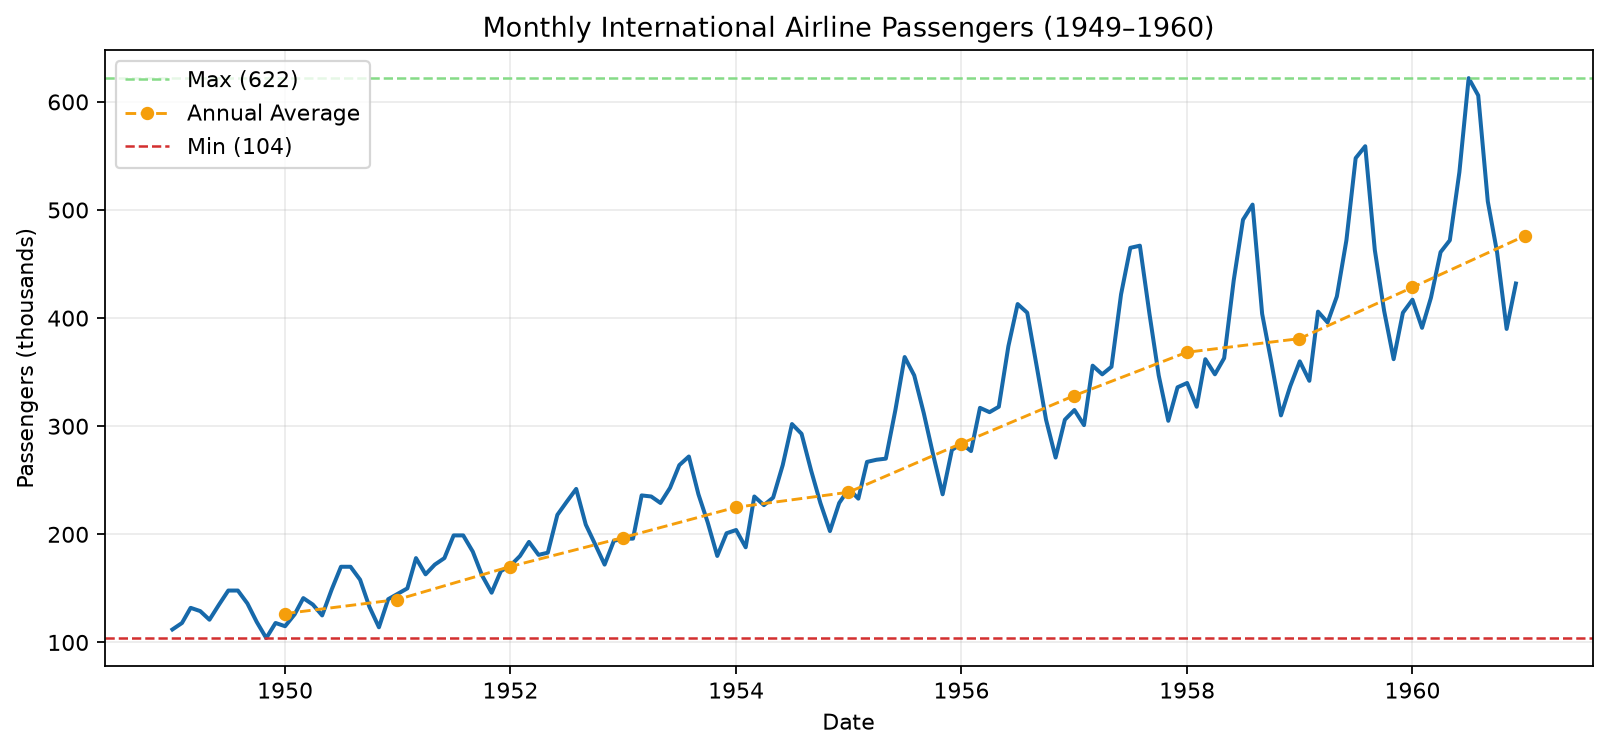

In [28]:
from practice_1.analysis import (
    build_month_year_matrix,
    compute_rolling_statistics,
    prepare_monthly_seasonal_data,
    summarize_monthly_pattern,
    validate_decomposition_series,
)
from practice_1.visualization import (
    plot_month_year_heatmap,
    plot_monthly_seasonal_pattern,
    plot_rolling_statistics,
    plot_time_series,
)

ROLLING_WINDOW = 12
ROLLING_MIN_PERIODS = 12
ROLLING_CENTER = False
ROLLING_STD_DDOF = 1

validated_e5_series = validate_decomposition_series(series)
if len(validated_e5_series) != 144:
    raise ValueError("E5 expected 144 validated observations")
if validated_e5_series.index[0] != pd.Timestamp("1949-01-01"):
    raise ValueError("E5 start timestamp does not match the approved contract")
if validated_e5_series.index[-1] != pd.Timestamp("1960-12-01"):
    raise ValueError("E5 end timestamp does not match the approved contract")
if validated_e5_series.isna().any():
    raise ValueError("E5 validated series unexpectedly contains missing values")

full_series_figure = FIGURES_DIR / "13_full_time_series.png"
plot_time_series(air_passengers_frame, full_series_figure)
display(Image(filename=str(full_series_figure)))

### Rolling statistics theo protocol đã khóa

Rolling mean và rolling standard deviation đều dùng cửa sổ **trailing 12 tháng**, `min_periods=12`, `center=False`; rolling standard deviation dùng `ddof=1`. Giá trị tại thời điểm hiện tại chỉ sử dụng observation hiện tại và 11 tháng trước đó, không dùng future observations. Vì chưa đủ một cửa sổ năm, 11 timestamp đầu tiên phải là `NaN`; đây là boundary behavior dự kiến và không được fill.

window,min_periods,center,std_ddof,initial_nan_count,first_valid_timestamp,last_rolling_mean,last_rolling_std
12,12,False,1,11,1949-12-01 00:00:00,476.1667,77.7371


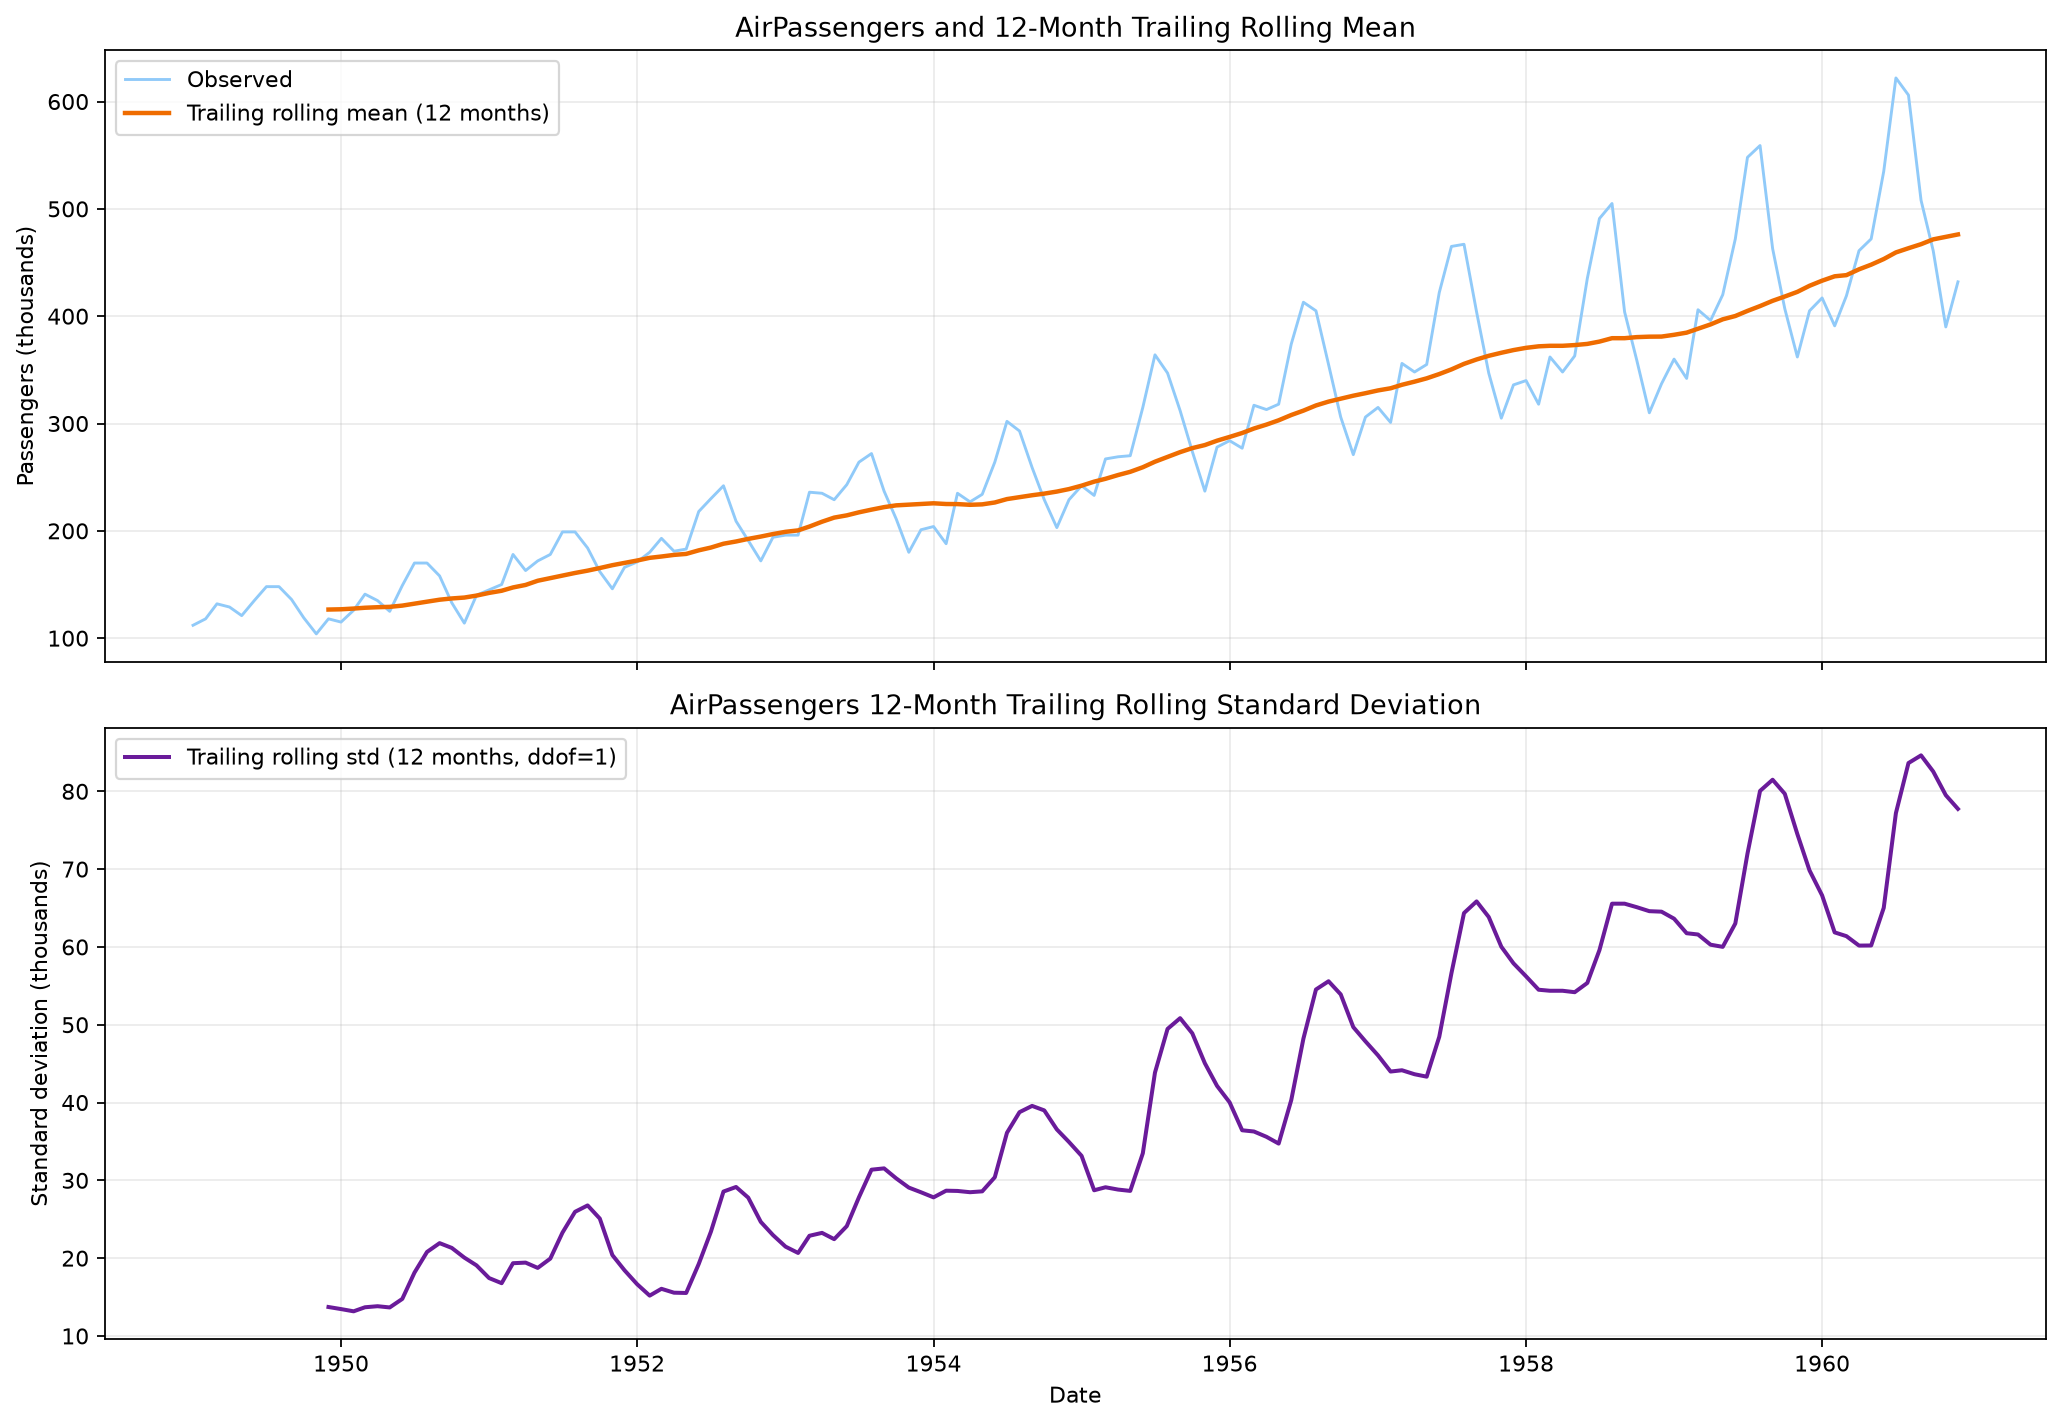

In [29]:
rolling_statistics = compute_rolling_statistics(
    validated_e5_series,
    window=ROLLING_WINDOW,
    min_periods=ROLLING_MIN_PERIODS,
    center=ROLLING_CENTER,
    std_ddof=ROLLING_STD_DDOF,
)
rolling_nan_counts = rolling_statistics[
    ["rolling_mean_12", "rolling_std_12"]
].isna().sum()
if not rolling_nan_counts.eq(11).all():
    raise ValueError("Rolling statistics must contain exactly 11 initial NaN values")
if rolling_statistics["rolling_mean_12"].first_valid_index() != pd.Timestamp("1949-12-01"):
    raise ValueError("Rolling mean first valid timestamp must be 1949-12-01")
if rolling_statistics["rolling_std_12"].first_valid_index() != pd.Timestamp("1949-12-01"):
    raise ValueError("Rolling std first valid timestamp must be 1949-12-01")

rolling_output = RESULTS_DIR / "rolling_statistics.csv"
rolling_statistics.reset_index().to_csv(rolling_output, index=False)
rolling_figure = FIGURES_DIR / "14_rolling_mean_std.png"
plot_rolling_statistics(rolling_statistics, rolling_figure)

rolling_validation = pd.DataFrame({
    "window": [ROLLING_WINDOW],
    "min_periods": [ROLLING_MIN_PERIODS],
    "center": [ROLLING_CENTER],
    "std_ddof": [ROLLING_STD_DDOF],
    "initial_nan_count": [int(rolling_nan_counts.iloc[0])],
    "first_valid_timestamp": [rolling_statistics["rolling_mean_12"].first_valid_index()],
    "last_rolling_mean": [rolling_statistics["rolling_mean_12"].iloc[-1]],
    "last_rolling_std": [rolling_statistics["rolling_std_12"].iloc[-1]],
})
display(visualise_table(
    rolling_validation,
    "Cấu hình và kiểm tra rolling statistics 12 tháng",
))
display(Image(filename=str(rolling_figure)))

month,month_name,mean_value,min_value,max_value
1,January,241.7500,112.0000,417.0000
2,February,235.0000,118.0000,391.0000
3,March,270.1667,132.0000,419.0000
4,April,267.0833,129.0000,461.0000
5,May,271.8333,121.0000,472.0000
6,June,311.6667,135.0000,535.0000
7,July,351.3333,148.0000,622.0000
8,August,351.0833,148.0000,606.0000
9,September,302.4167,136.0000,508.0000
10,October,266.5833,119.0000,461.0000


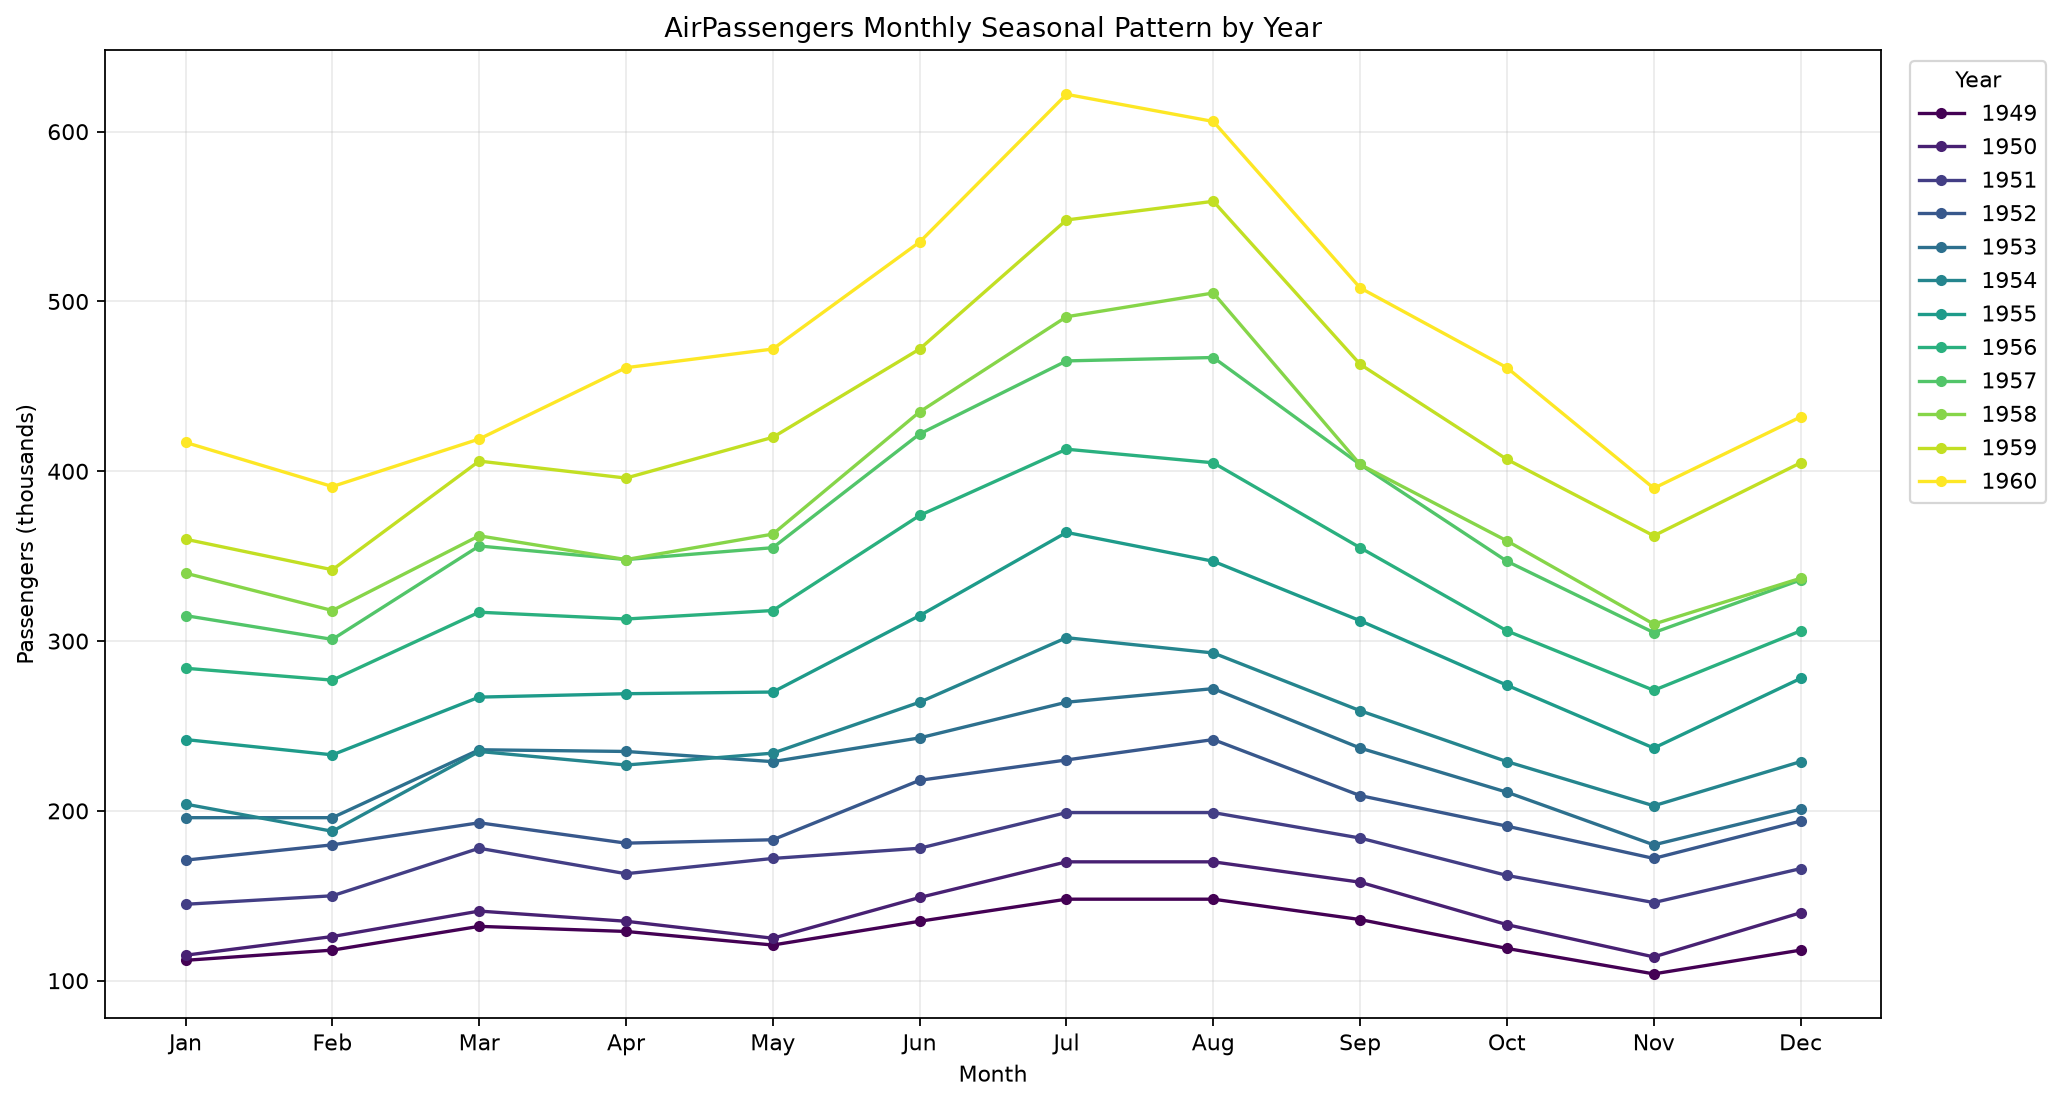

In [30]:
seasonal_data_e5 = prepare_monthly_seasonal_data(validated_e5_series)
monthly_summary = summarize_monthly_pattern(seasonal_data_e5)
month_labels = {
    1: "January", 2: "February", 3: "March", 4: "April",
    5: "May", 6: "June", 7: "July", 8: "August",
    9: "September", 10: "October", 11: "November", 12: "December",
}
monthly_summary_display = monthly_summary.copy()
monthly_summary_display.insert(
    1,
    "month_name",
    monthly_summary_display["month"].map(month_labels),
)

seasonal_figure = FIGURES_DIR / "15_monthly_seasonal_plot.png"
plot_monthly_seasonal_pattern(seasonal_data_e5, seasonal_figure)
display(visualise_table(
    monthly_summary_display,
    "Thống kê hành khách theo tháng",
    gradient_columns=["mean_value", "min_value", "max_value"],
))
display(Image(filename=str(seasonal_figure)))

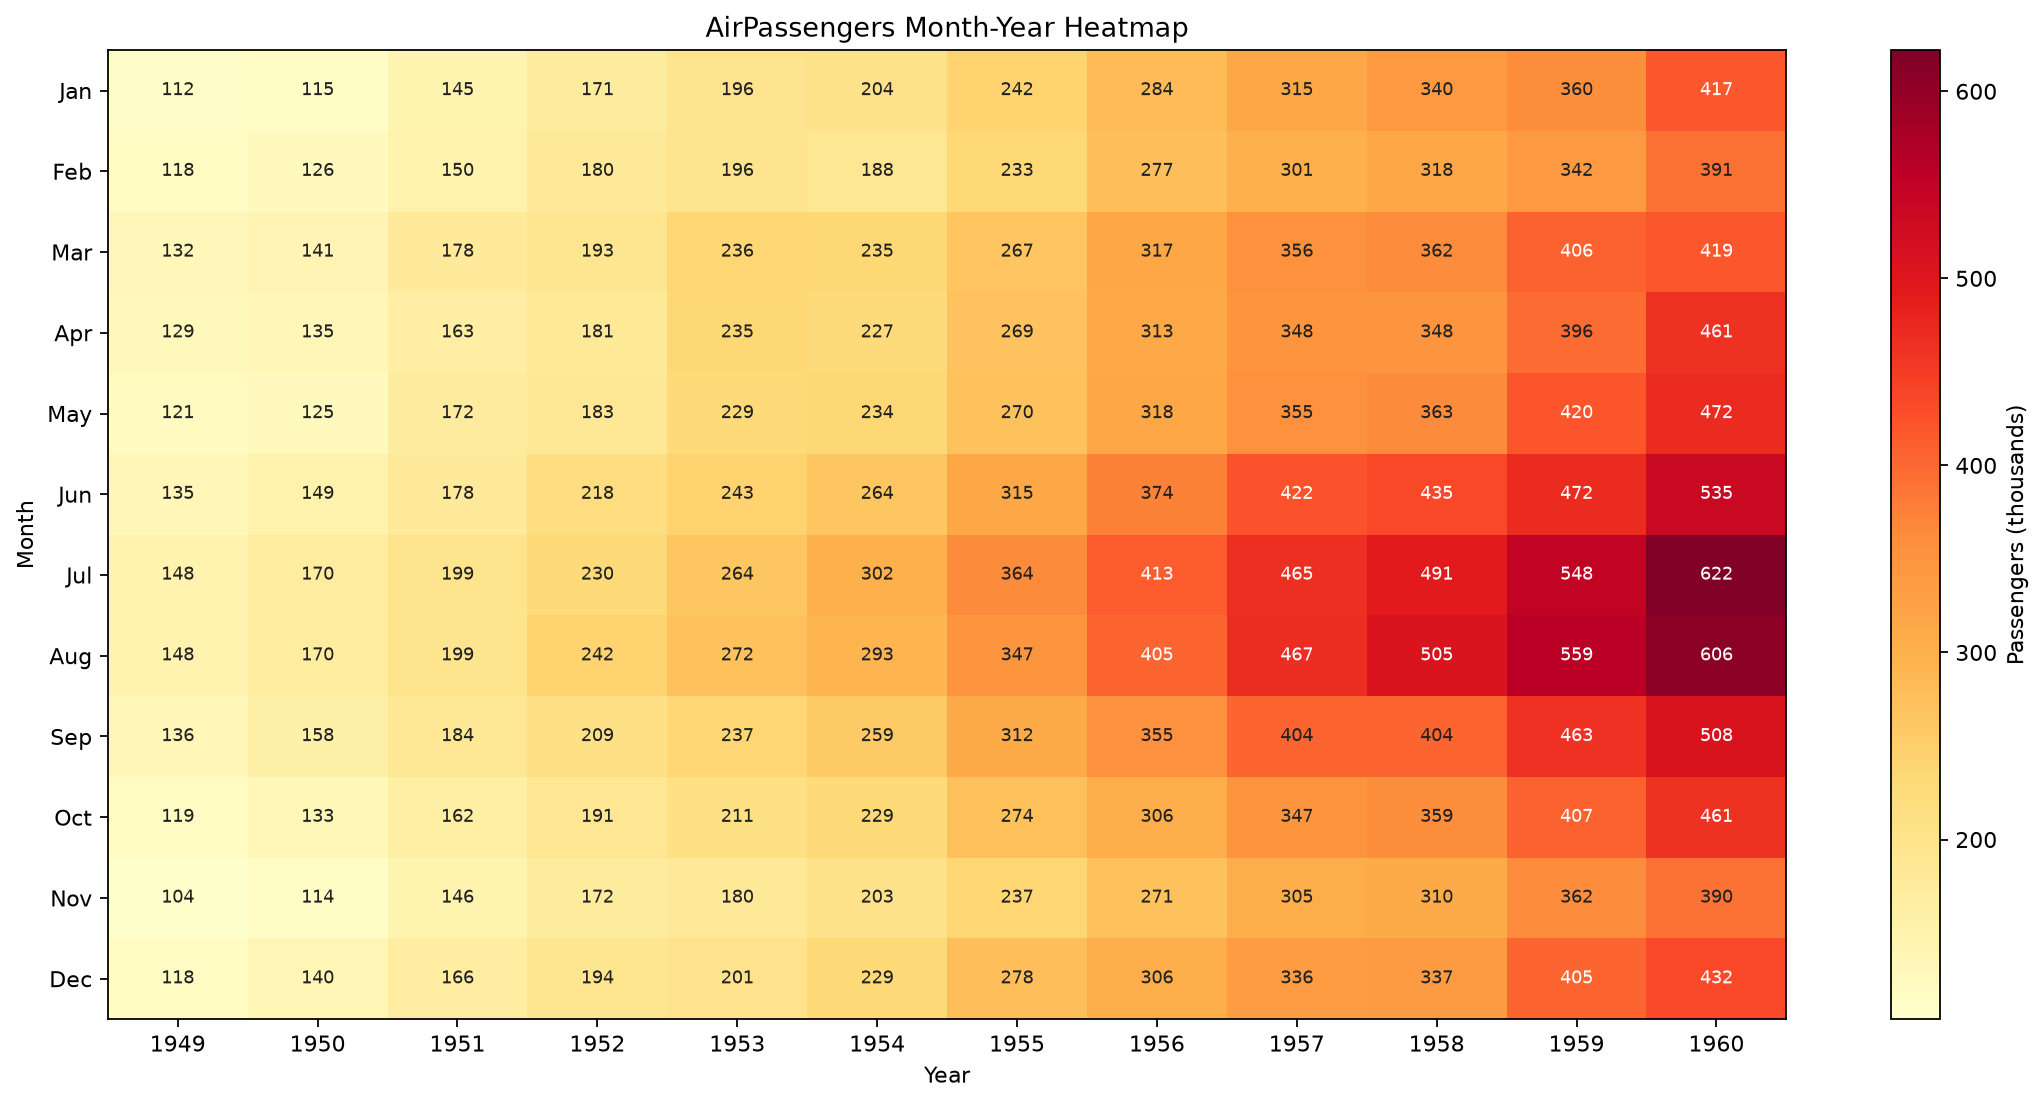

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
1,112,115,145,171,196,204,242,284,315,340,360,417
2,118,126,150,180,196,188,233,277,301,318,342,391
3,132,141,178,193,236,235,267,317,356,362,406,419
4,129,135,163,181,235,227,269,313,348,348,396,461
5,121,125,172,183,229,234,270,318,355,363,420,472
6,135,149,178,218,243,264,315,374,422,435,472,535
7,148,170,199,230,264,302,364,413,465,491,548,622
8,148,170,199,242,272,293,347,405,467,505,559,606
9,136,158,184,209,237,259,312,355,404,404,463,508


timestamp,observed_value,residual_log,flag
1950-01-01 00:00:00,115.0000,-0.0694,True
1950-05-01 00:00:00,125.0000,-0.0681,True
1950-11-01 00:00:00,114.0000,-0.0684,True
1951-03-01 00:00:00,178.0000,0.0720,True
1951-05-01 00:00:00,172.0000,0.0874,True
1953-03-01 00:00:00,236.0000,0.0813,True
1953-04-01 00:00:00,235.0000,0.1156,True
1953-05-01 00:00:00,229.0000,0.0883,True
1954-01-01 00:00:00,204.0000,-0.0440,True
1954-02-01 00:00:00,188.0000,-0.1131,True


In [31]:
month_year_matrix = build_month_year_matrix(
    seasonal_data_e5,
    expected_shape=(12, 12),
)
if month_year_matrix.index.tolist() != list(range(1, 13)):
    raise ValueError("Heatmap month order must be January through December")
if month_year_matrix.columns.tolist() != list(range(1949, 1961)):
    raise ValueError("Heatmap year order must be 1949 through 1960")

e1_acf_evidence = pd.read_csv(RESULTS_DIR / "acf_values.csv")
e3_residual_evidence = pd.read_csv(RESULTS_DIR / "residual_diagnostics.csv")
e4_candidate_evidence = pd.read_csv(
    RESULTS_DIR / "outlier_candidates.csv",
    parse_dates=["timestamp"],
)
if e1_acf_evidence.columns.tolist() != ["lag", "acf", "lower_ci", "upper_ci"]:
    raise ValueError("E1 ACF evidence has an unexpected schema")
if e3_residual_evidence.columns.tolist() != ["lag", "ljung_box_statistic", "p_value"]:
    raise ValueError("E3 residual evidence has an unexpected schema")
if len(e4_candidate_evidence) != 14 or not e4_candidate_evidence["flag"].all():
    raise ValueError("E4 outlier evidence does not match the validated 14-candidate result")
if not e4_candidate_evidence["timestamp"].isin(validated_e5_series.index).all():
    raise ValueError("E4 candidate timestamps do not align with AirPassengers")

heatmap_figure = FIGURES_DIR / "16_month_year_heatmap.png"
plot_month_year_heatmap(month_year_matrix, heatmap_figure)

rolling_valid = rolling_statistics.dropna()
rolling_level_std_correlation = float(
    rolling_valid["rolling_mean_12"].corr(rolling_valid["rolling_std_12"])
)
early_rolling_std = float(rolling_valid["rolling_std_12"].iloc[:36].mean())
late_rolling_std = float(rolling_valid["rolling_std_12"].iloc[-36:].mean())
annual_amplitude = seasonal_data_e5.groupby("year")["observed_value"].agg(
    lambda values: values.max() - values.min()
)
early_amplitude = float(annual_amplitude.iloc[:3].mean())
late_amplitude = float(annual_amplitude.iloc[-3:].mean())

display(Image(filename=str(heatmap_figure)))
display(visualise_table(
    month_year_matrix,
    "Ma trận AirPassengers theo tháng và năm",
    hide_index=False,
    precision=0,
    gradient_columns=list(month_year_matrix.columns),
    gradient_axis=None,
    gradient_cmap="YlOrRd",
))
e4_candidates_display = e4_candidate_evidence[
    ["timestamp", "observed_value", "residual_log", "flag"]
]
e4_residual_limit = float(e4_candidates_display["residual_log"].abs().max())
display(
    visualise_table(
        e4_candidates_display,
        "E4 outlier candidates được đối chiếu trong E5",
    )
    .background_gradient(
        cmap="coolwarm",
        subset=["residual_log"],
        axis=None,
        vmin=-e4_residual_limit,
        vmax=e4_residual_limit,
    )
    .map(
        lambda value: boolean_cell_color(value, alert=True),
        subset=["flag"],
    )
)

In [32]:
peak_month = int(monthly_summary.loc[monthly_summary["mean_value"].idxmax(), "month"])
low_month = int(monthly_summary.loc[monthly_summary["mean_value"].idxmin(), "month"])
peak_month_mean = float(monthly_summary.loc[monthly_summary["month"].eq(peak_month), "mean_value"].iloc[0])
low_month_mean = float(monthly_summary.loc[monthly_summary["month"].eq(low_month), "mean_value"].iloc[0])
global_max_timestamp = validated_e5_series.idxmax()
global_max_value = float(validated_e5_series.max())
visualization_markdown = chr(10).join([
    "## Kết luận Exercise 5",
    "",
    f"- **Xu hướng chung:** Chuỗi tăng rõ từ 1949 đến 1960; trailing rolling mean 12 tháng đạt **{rolling_statistics['rolling_mean_12'].iloc[-1]:.2f} nghìn** tại 1960-12. Rolling std trung bình tăng từ **{early_rolling_std:.2f}** ở nhóm đầu lên **{late_rolling_std:.2f} nghìn** ở nhóm cuối, với tương quan rolling mean–std **{rolling_level_std_correlation:.3f}**, cho thấy variability trên thang gốc tăng theo level.",
    "",
    f"- **Mùa vụ nổi bật:** Pattern lặp theo chu kỳ 12 tháng, cao nhất vào **{month_labels[peak_month]}** với mean **{peak_month_mean:.2f} nghìn** và thấp nhất vào **{month_labels[low_month]}** với mean **{low_month_mean:.2f} nghìn**. Biên độ trung bình tăng từ **{early_amplitude:.2f}** ở ba năm đầu lên **{late_amplitude:.2f} nghìn** ở ba năm cuối.",
    "",
    f"- **Bất thường (nếu có):** Giá trị lớn nhất là **{global_max_value:.0f} nghìn tại {global_max_timestamp:%Y-%m}**, nhưng nằm trong mùa cao điểm và ở mức nền cuối kỳ nên không đủ để kết luận là anomaly. E4 flag **{len(e4_candidate_evidence)}** residual-based candidates cần kiểm tra thêm; chưa có bất thường nào được xác nhận và E5 không tự động xóa, clip hoặc thay thế dữ liệu.",
])
display(Markdown(visualization_markdown))

## Kết luận Exercise 5

- **Xu hướng chung:** Chuỗi tăng rõ từ 1949 đến 1960; trailing rolling mean 12 tháng đạt **476.17 nghìn** tại 1960-12. Rolling std trung bình tăng từ **19.47** ở nhóm đầu lên **66.73 nghìn** ở nhóm cuối, với tương quan rolling mean–std **0.959**, cho thấy variability trên thang gốc tăng theo level.

- **Mùa vụ nổi bật:** Pattern lặp theo chu kỳ 12 tháng, cao nhất vào **July** với mean **351.33 nghìn** và thấp nhất vào **November** với mean **232.83 nghìn**. Biên độ trung bình tăng từ **51.33** ở ba năm đầu lên **214.67 nghìn** ở ba năm cuối.

- **Bất thường (nếu có):** Giá trị lớn nhất là **622 nghìn tại 1960-07**, nhưng nằm trong mùa cao điểm và ở mức nền cuối kỳ nên không đủ để kết luận là anomaly. E4 flag **14** residual-based candidates cần kiểm tra thêm; chưa có bất thường nào được xác nhận và E5 không tự động xóa, clip hoặc thay thế dữ liệu.